# **Interacción Radiación-Materia — Hoja 2 de problemas**
### Interacción de partículas cargadas con la materia

Este cuaderno contiene la resolución detallada de la **Hoja 2** de problemas (poder de frenado, alcance, curva de Bragg, pérdidas radiativas de electrones...). Cada problema incluye:

* El **enunciado**.
* La **resolución razonada** en Markdown, con las ecuaciones necesarias.
* Una celda de **cálculo en Python** que reproduce los resultados numéricos.
* En muchos casos, **gráficas** y **widgets interactivos** para explorar la física del problema más allá de los valores concretos del enunciado.

### **Preparativos**
La siguiente celda ha de ejecutarse para cargar las librerías y datos necesarios para el correcto funcionamiento de este cuaderno

In [1]:
import os

# 1. Definir los datos del repositorio
USUARIO_GH = "nietootein"
REPOSITORIO_GH = "nirma"

# 2. Resetear siempre al directorio base ("home") de Google Colab
# Esto garantiza que el punto de partida sea idéntico en cada ejecución
directorio_home = '/content'
if os.path.exists(directorio_home):
    os.chdir(directorio_home)
print(f"🏠 Partiendo del directorio de inicio: {os.getcwd()}")

# 3. Clonar el repositorio solo si no existe (y si no estamos ya dentro de él)
if os.path.basename(os.getcwd()) == REPOSITORIO_GH:
    print(f"ℹ️ Ya estamos dentro del repositorio '{REPOSITORIO_GH}'.")
elif os.path.basename(os.getcwd()) == 'notebooks' and os.path.exists('../data'):
    os.chdir('..')
    print("ℹ️ Ejecución local detectada: subiendo a la raíz del repositorio.")
else:
    if not os.path.exists(REPOSITORIO_GH):
        print(f"📦 Clonando el repositorio '{REPOSITORIO_GH}'...")
        !git clone https://github.com/{USUARIO_GH}/{REPOSITORIO_GH}.git
    else:
        print(f"ℹ️ El repositorio '{REPOSITORIO_GH}' ya está disponible en el directorio base.")
    # 4. Entrar en la carpeta del proyecto para que las rutas relativas funcionen
    os.chdir(REPOSITORIO_GH)
print(f"📂 Directorio de trabajo activo establecido en: {os.getcwd()}")

# 5. Importar librerías de Python
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact
from IPython.display import display
from scipy.integrate import trapezoid, cumulative_trapezoid

sns.set_theme(style='whitegrid', palette='colorblind', font='DejaVu Sans')

🏠 Partiendo del directorio de inicio: /home/claude/nirma/notebooks
ℹ️ Ejecución local detectada: subiendo a la raíz del repositorio.
📂 Directorio de trabajo activo establecido en: /home/claude/nirma


#### **Constantes y funciones auxiliares comunes**
A lo largo de la hoja trabajaremos a menudo con **tablas de poder de frenado** $S(E)$ (de las bases de datos ESTAR, PSTAR y ASTAR del NIST). Dos operaciones se repiten constantemente:

1. **Interpolar** la tabla. Como $S(E)$ varía como una ley de potencias en amplios rangos, la interpolación más fiel es **lineal en escala log-log**.
2. **Integrar** $dE/S(E)$ para obtener el alcance en la aproximación de frenado continuo (CSDA, *Continuous Slowing Down Approximation*):
$$ R(E_0) = \int_0^{E_0} \frac{dE}{S(E)} $$
y, a partir de ella, la **curva de Bragg** $S(E(x))$ frente a la profundidad $x$, usando que el alcance residual en el punto $x$ es $R(E(x)) = R(E_0) - x$.

La siguiente celda define estas herramientas (ejecútala antes de continuar).

In [2]:
# =====================================================================
# CONSTANTES FÍSICAS
# =====================================================================
me_c2 = 0.511          # Energía en reposo del electrón (MeV)
K_BB = 0.307075        # 4·π·r0²·me·c²·Na  (MeV cm² / mol)
NA = 6.022e23          # Número de Avogadro (mol^-1)

# =====================================================================
# FUNCIONES AUXILIARES
# =====================================================================
def interp_loglog(x, xp, fp):
    # Interpolación lineal en escala log-log de una tabla (xp, fp)
    return np.exp(np.interp(np.log(x), np.log(xp), np.log(fp)))

def alcance_csda(E_tab, S_tab, E_min, E_max, n=5000):
    # Alcance CSDA (g/cm²) = ∫ dE / S(E) entre E_min y E_max (malla logarítmica)
    E = np.logspace(np.log10(E_min), np.log10(E_max), n)
    return trapezoid(1.0 / interp_loglog(E, E_tab, S_tab), E)

def curva_bragg(E_tab, S_tab, E0, E_min, n=5000):
    # Devuelve la profundidad x (g/cm²), la energía E(x) y el poder de frenado S(E(x))
    # a lo largo de la trayectoria de una partícula de energía inicial E0.
    E = np.logspace(np.log10(E_min), np.log10(E0), n)
    S = interp_loglog(E, E_tab, S_tab)
    R_res = cumulative_trapezoid(1.0 / S, E, initial=0.0)   # alcance residual R(E) - R(E_min)
    x = R_res[-1] - R_res                                     # profundidad recorrida
    return x[::-1], E[::-1], S[::-1]                          # ordenado de x = 0 a x = R

print("✅ Constantes y funciones auxiliares cargadas.")

✅ Constantes y funciones auxiliares cargadas.


### **Problema 1**
Empleando los datos de la gráfica adjunta hallar el espesor lineal en aire (condiciones normales) necesario para reducir en 100 keV la energía de un haz monoenergético de partículas $\alpha$ de 5 MeV. Calcular de forma aproximada el espesor necesario para una reducción de 2 MeV. Repetir los cálculos para aluminio. Estimar el alcance en aire (c.n.) de partículas $\alpha$ de 5 MeV sabiendo que para 0.5 MeV es de 0.3 cm. Representar la energía perdida por unidad de longitud frente al camino recorrido (gráfica de Bragg).

**DATOS:** $\rho(\text{aire}) = 1.2 \times 10^{-3}\text{ g cm}^{-3}$, $\rho(\text{aluminio}) = 2.7\text{ g cm}^{-3}$.

*(La gráfica del enunciado muestra el poder de frenado másico $\frac{1}{\rho}\frac{dE}{dx}$ de partículas $\alpha$ en aluminio y en aire entre 0.1 y 10 MeV, en escala log-log.)*

---

#### **Lectura de la gráfica**
Leemos en la gráfica los poderes de frenado másicos que necesitamos (en la celda de cálculo se incluye una tabla con la curva completa digitalizada):

| $E$ (MeV) | $S_{aire}$ (MeV cm²/g) | $S_{Al}$ (MeV cm²/g) |
| :---: | :---: | :---: |
| 3.0 | $\approx 1070$ | $\approx 820$ |
| 4.0 | $\approx 890$ | $\approx 700$ |
| 5.0 | $\approx 760$ | $\approx 605$ |

El poder de frenado **lineal** (pérdida de energía por unidad de longitud) se obtiene multiplicando por la densidad: $\left(\frac{dE}{dx}\right) = \rho \cdot S$.

---

#### **a) Reducción de 100 keV (aproximación de absorbente delgado)**
Como $\Delta E = 0.1\text{ MeV} \ll E_0 = 5\text{ MeV}$, el poder de frenado apenas cambia a lo largo del recorrido y podemos considerarlo **constante** e igual a su valor a 5 MeV:
$$ \Delta x \approx \frac{\Delta E}{\rho\, S(E_0)} $$

* **Aire:** $\rho S = 1.2\times10^{-3} \times 761 = 0.913\text{ MeV/cm}$
$$ \Delta x_{aire} = \frac{0.1}{0.913} \approx \mathbf{0.11\text{ cm}} \;(\approx 1.1\text{ mm}) $$
* **Aluminio:** $\rho S = 2.7 \times 605 = 1634\text{ MeV/cm}$
$$ \Delta x_{Al} = \frac{0.1}{1634} \approx 6.1\times10^{-5}\text{ cm} = \mathbf{0.61\ \mu m} $$

---

#### **b) Reducción de 2 MeV (de 5 a 3 MeV)**
Ahora $S$ varía apreciablemente entre 5 y 3 MeV ($760 \to 1070$ MeV cm²/g en aire). La forma exacta es integrar:
$$ \Delta x = \int_{3}^{5} \frac{dE}{\rho\, S(E)} $$
Una **aproximación razonable** es tomar el poder de frenado en la energía media del intervalo, $\bar{E} = 4\text{ MeV}$:

* **Aire:** $\Delta x \approx \dfrac{2}{1.2\times10^{-3}\times 887} \approx \mathbf{1.88\text{ cm}}$
* **Aluminio:** $\Delta x \approx \dfrac{2}{2.7\times 700} \approx 1.06\times10^{-3}\text{ cm} = \mathbf{10.6\ \mu m}$

La integración numérica de la curva completa (celda siguiente) da prácticamente el mismo resultado (1.88 cm y 10.6 µm), porque en este intervalo $1/S$ es casi lineal en $E$.

> **Comparación de materiales:** aunque el aluminio tiene un poder de frenado *másico* algo menor que el aire (menor $Z/A$ y mayor potencial de ionización $I$), su densidad es $\sim 2250$ veces mayor. Por eso, en espesor **lineal**, el aluminio frena las $\alpha$ unas 1800 veces más rápido: basta una hoja de papel de aluminio (~20 µm) para detenerlas.

---

#### **c) Alcance en aire de partículas $\alpha$ de 5 MeV**
El alcance se descompone en el tramo de 5 a 0.5 MeV más el alcance residual a 0.5 MeV (dato):
$$ R(5\text{ MeV}) = R(0.5\text{ MeV}) + \int_{0.5}^{5} \frac{dE}{\rho\, S(E)} $$
Integrando numéricamente la curva de la gráfica:
$$ R(5\text{ MeV}) \approx 0.3\text{ cm} + 3.29\text{ cm} \approx \mathbf{3.6\text{ cm}} $$

Este valor es coherente con la regla empírica de Geiger para el aire, $R(\text{cm}) \approx 0.318\, E^{3/2}(\text{MeV}) = 3.56\text{ cm}$.

---

#### **d) Curva de Bragg**
Para representar $-dE/dx$ frente al camino recorrido, calculamos para cada energía $E$ entre 5 MeV y 0 la profundidad alcanzada $x(E) = R(E_0) - R(E)$ y representamos $\rho S(E)$ frente a $x$. El resultado es la característica **curva de Bragg**: la pérdida de energía crece lentamente al principio, alcanza un **máximo pronunciado (pico de Bragg)** al final del recorrido (cuando $E \approx 0.7$ MeV, máximo de $S$) y cae bruscamente a cero.

                RESULTADOS NUMÉRICOS (PROBLEMA 1)                    
S(5 MeV) aire = 761 MeV cm²/g  ->  dE/dx = 0.913 MeV/cm
S(5 MeV) Al   = 605 MeV cm²/g  ->  dE/dx = 1634 MeV/cm
---------------------------------------------------------------------
a) Espesor para perder 100 keV:
   -> Aire:      0.110 cm
   -> Aluminio:  0.61 µm
---------------------------------------------------------------------
b) Espesor para perder 2 MeV (5 -> 3 MeV):     S(4 MeV)      Integral
   -> Aire:                                   1.881 cm     1.878 cm
   -> Aluminio:                               10.58 µm     10.61 µm
---------------------------------------------------------------------
c) Alcance en aire de α de 5 MeV:
   -> Tramo 5 -> 0.5 MeV:       3.29 cm
   -> R(5 MeV) = 0.3 + tramo =  3.59 cm   (regla de Geiger: 3.56 cm)


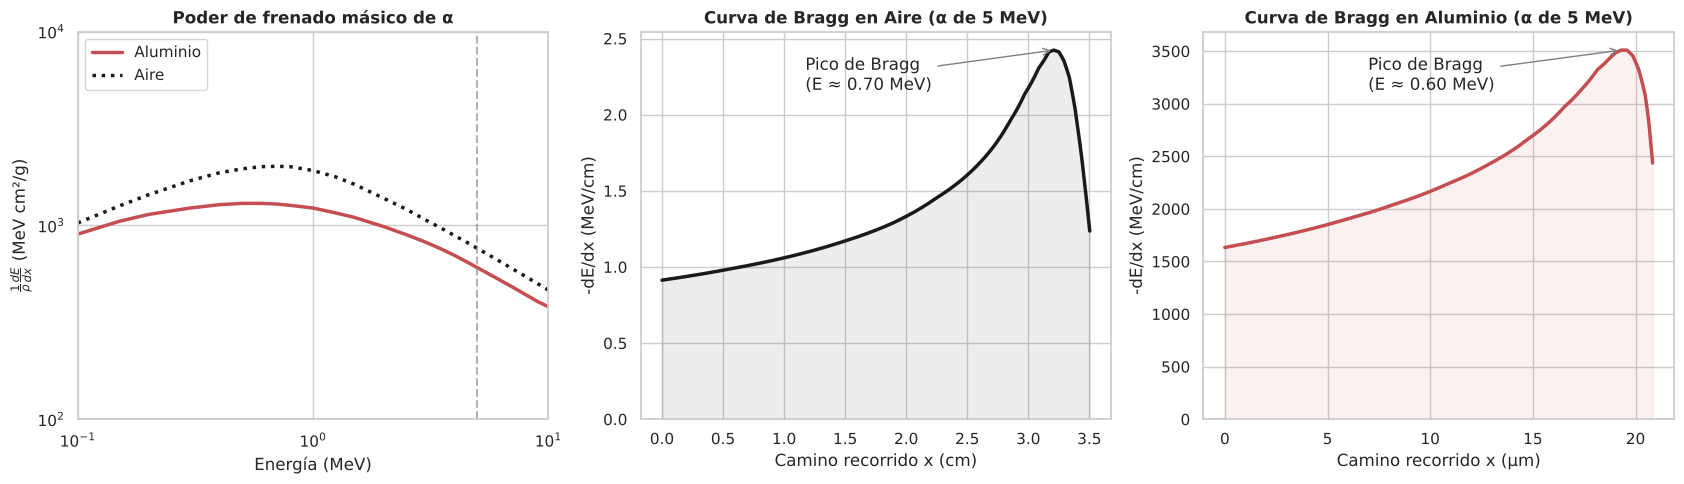

Nota: la curva de Bragg se ha cortado en E = 0.1 MeV (límite inferior de la gráfica);
      el último tramo (< 0.1 MeV) apenas añade unas décimas de mm en aire.


In [3]:
# =====================================================================
# 1. DATOS DE ENTRADA: curvas digitalizadas de la gráfica del enunciado
# =====================================================================
rho_aire = 1.2e-3      # g/cm^3
rho_Al = 2.7           # g/cm^3

E_graf = np.array([0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0, 1.25, 1.5,
                   2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0])   # MeV
S_aire_graf = np.array([1030, 1260, 1440, 1700, 1870, 1960, 2010, 2020, 2010, 1920, 1780, 1630,
                        1380, 1210, 1070, 969, 886, 819, 761, 670, 600, 546, 501, 464])   # MeV cm²/g
S_Al_graf = np.array([902, 1050, 1140, 1230, 1280, 1300, 1300, 1290, 1270, 1230, 1160, 1100,
                      986, 895, 821, 757, 700, 649, 605, 536, 483, 440, 405, 381])         # MeV cm²/g

E0 = 5.0               # MeV
R_05_aire = 0.3        # cm (alcance en aire a 0.5 MeV, dato)

S_aire = lambda E: interp_loglog(E, E_graf, S_aire_graf)
S_Al = lambda E: interp_loglog(E, E_graf, S_Al_graf)

def espesor_integrado(S_func, rho, E_ini, E_fin, n=4000):
    # Espesor lineal (cm) para pasar de E_ini a E_fin integrando dE/(rho·S)
    E = np.linspace(E_fin, E_ini, n)
    return trapezoid(1.0 / (rho * S_func(E)), E)

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
# a) Pérdida de 100 keV (S constante)
dx_aire_100 = 0.1 / (rho_aire * S_aire(E0))
dx_Al_100 = 0.1 / (rho_Al * S_Al(E0))

# b) Pérdida de 2 MeV: aproximación con S(E medio = 4 MeV) e integración exacta
dx_aire_2_aprox = 2.0 / (rho_aire * S_aire(4.0))
dx_Al_2_aprox = 2.0 / (rho_Al * S_Al(4.0))
dx_aire_2_int = espesor_integrado(S_aire, rho_aire, 5.0, 3.0)
dx_Al_2_int = espesor_integrado(S_Al, rho_Al, 5.0, 3.0)

# c) Alcance en aire a 5 MeV
tramo_05_5 = espesor_integrado(S_aire, rho_aire, 5.0, 0.5)
R_5_aire = R_05_aire + tramo_05_5
R_Geiger = 0.318 * E0**1.5

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 1)                    ")
print("=====================================================================")
print(f"S(5 MeV) aire = {S_aire(E0):.0f} MeV cm²/g  ->  dE/dx = {rho_aire*S_aire(E0):.3f} MeV/cm")
print(f"S(5 MeV) Al   = {S_Al(E0):.0f} MeV cm²/g  ->  dE/dx = {rho_Al*S_Al(E0):.0f} MeV/cm")
print("-" * 69)
print("a) Espesor para perder 100 keV:")
print(f"   -> Aire:      {dx_aire_100:.3f} cm")
print(f"   -> Aluminio:  {dx_Al_100*1e4:.2f} µm")
print("-" * 69)
print("b) Espesor para perder 2 MeV (5 -> 3 MeV):     S(4 MeV)      Integral")
print(f"   -> Aire:                                  {dx_aire_2_aprox:6.3f} cm    {dx_aire_2_int:6.3f} cm")
print(f"   -> Aluminio:                              {dx_Al_2_aprox*1e4:6.2f} µm    {dx_Al_2_int*1e4:6.2f} µm")
print("-" * 69)
print("c) Alcance en aire de α de 5 MeV:")
print(f"   -> Tramo 5 -> 0.5 MeV:       {tramo_05_5:.2f} cm")
print(f"   -> R(5 MeV) = 0.3 + tramo =  {R_5_aire:.2f} cm   (regla de Geiger: {R_Geiger:.2f} cm)")
print("=====================================================================")

# =====================================================================
# 4. GRÁFICAS: poder de frenado y curvas de Bragg
# =====================================================================
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Panel 1: reproducción de la gráfica del enunciado
ax = axes[0]
ax.loglog(E_graf, S_Al_graf, '-', color='#c44e52', lw=2.5, label='Aluminio')
ax.loglog(E_graf, S_aire_graf, 'k:', lw=2.5, label='Aire')
ax.axvline(E0, color='gray', ls='--', alpha=0.6)
ax.set_xlim(0.1, 10); ax.set_ylim(100, 1e4)
ax.set_xlabel('Energía (MeV)'); ax.set_ylabel(r'$\frac{1}{\rho}\frac{dE}{dx}$ (MeV cm²/g)')
ax.set_title('Poder de frenado másico de α', fontweight='bold')
ax.legend()

# Paneles 2 y 3: curvas de Bragg (dE/dx lineal frente a x) desde 5 MeV hasta 0.1 MeV
for ax, Sf, rho, nombre, factor, unidad, color in [
        (axes[1], S_aire, rho_aire, 'Aire', 1.0, 'cm', 'k'),
        (axes[2], S_Al, rho_Al, 'Aluminio', 1e4, 'µm', '#c44e52')]:
    E_tray = np.linspace(E0, 0.1, 2000)
    x_tray = cumulative_trapezoid(-1.0 / (rho * Sf(E_tray)), E_tray, initial=0.0)   # cm
    ax.plot(x_tray * factor, rho * Sf(E_tray), color=color, lw=2.5)
    ax.fill_between(x_tray * factor, rho * Sf(E_tray), color=color, alpha=0.08)
    i_max = np.argmax(Sf(E_tray))
    ax.annotate(f'Pico de Bragg\n(E ≈ {E_tray[i_max]:.2f} MeV)',
                xy=(x_tray[i_max] * factor, rho * Sf(E_tray[i_max])),
                xytext=(0.35, 0.85), textcoords='axes fraction',
                arrowprops=dict(arrowstyle='->', color='gray'))
    ax.set_xlabel(f'Camino recorrido x ({unidad})')
    ax.set_ylabel('-dE/dx (MeV/cm)')
    ax.set_title(f'Curva de Bragg en {nombre} (α de 5 MeV)', fontweight='bold')
    ax.set_ylim(0, None)

plt.tight_layout()
plt.show()
print("Nota: la curva de Bragg se ha cortado en E = 0.1 MeV (límite inferior de la gráfica);")
print("      el último tramo (< 0.1 MeV) apenas añade unas décimas de mm en aire.")

#### **Bonus: ¿cuándo es válida la aproximación de absorbente delgado?**

En el apartado **a)** hemos supuesto que $S$ es constante a lo largo del recorrido ($\Delta x \approx \Delta E / \rho S(E_0)$), igual que en el Problema 1 de la Hoja 1 aproximábamos $P \approx \mu x$ para un blanco fino. El siguiente widget compara, para aire y aluminio, tres maneras de calcular el espesor necesario para perder una energía $\Delta E$:

1. **S constante** evaluado en la energía inicial $E_0$ (absorbente delgado).
2. **S evaluado en la energía media** $E_0 - \Delta E/2$.
3. **Integración exacta** $\int dE/\rho S(E)$.

**Cuestiones:**
* Con $E_0 = 5$ MeV, ¿a partir de qué $\Delta E$ el error de la aproximación de absorbente delgado supera el 10 %?
* ¿Por qué la aproximación con la energía media funciona tan bien incluso para $\Delta E$ grandes? ¿Qué ocurre cuando el intervalo de energías incluye el máximo de $S(E)$ (por ejemplo, $E_0 = 1.5$ MeV y $\Delta E = 1.2$ MeV)?
* ¿El *cociente* entre los espesores en aire y aluminio depende mucho de $\Delta E$? ¿Por qué?

In [4]:
def widget_absorbente_delgado(E0_w, dE_w):
    if dE_w >= E0_w - 0.1:
        dE_w = E0_w - 0.1
        print(f"⚠️ ΔE limitado a {dE_w:.2f} MeV (la gráfica sólo llega hasta 0.1 MeV).")
    E_fin = E0_w - dE_w
    resultados = {}
    for nombre, Sf, rho, factor, unidad in [('Aire', S_aire, rho_aire, 1.0, 'cm'),
                                             ('Aluminio', S_Al, rho_Al, 1e4, 'µm')]:
        d1 = dE_w / (rho * Sf(E0_w)) * factor
        d2 = dE_w / (rho * Sf(E0_w - dE_w / 2)) * factor
        d3 = espesor_integrado(Sf, rho, E0_w, E_fin) * factor
        resultados[nombre] = (d1, d2, d3, unidad)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    # Panel izquierdo: S(E) con el intervalo de energías sombreado
    ax = axes[0]
    ax.loglog(E_graf, S_Al_graf, '-', color='#c44e52', lw=2, label='Aluminio')
    ax.loglog(E_graf, S_aire_graf, 'k:', lw=2, label='Aire')
    ax.axvspan(E_fin, E0_w, color='gold', alpha=0.3, label=f'Intervalo {E_fin:.2f} – {E0_w:.2f} MeV')
    ax.set_xlim(0.1, 10); ax.set_ylim(200, 4000)
    ax.set_xlabel('Energía (MeV)'); ax.set_ylabel('S (MeV cm²/g)')
    ax.set_title('Poder de frenado en el intervalo de pérdida', fontweight='bold')
    ax.legend(loc='lower left')

    # Panel derecho: error relativo de las aproximaciones respecto a la integral
    ax = axes[1]
    etiquetas = ['S(E₀)\n(absorbente delgado)', 'S(E medio)']
    x_pos = np.arange(2)
    for k, (nombre, color) in enumerate([('Aire', '#4c72b0'), ('Aluminio', '#c44e52')]):
        d1, d2, d3, _ = resultados[nombre]
        errores = [100 * (d1 - d3) / d3, 100 * (d2 - d3) / d3]
        barras = ax.bar(x_pos + (k - 0.5) * 0.35, errores, width=0.35, color=color, label=nombre)
        ax.bar_label(barras, fmt='%.1f%%', padding=3)
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xticks(x_pos); ax.set_xticklabels(etiquetas)
    ax.set_ylabel('Error relativo respecto a la integral (%)')
    ax.set_title('Calidad de las aproximaciones', fontweight='bold')
    ax.legend()
    plt.tight_layout(); plt.show()

    print(f"{'Medio':<10} | {'S(E0)':>12} | {'S(E medio)':>12} | {'Integral':>12}")
    print("-" * 56)
    for nombre, (d1, d2, d3, u) in resultados.items():
        print(f"{nombre:<10} | {d1:9.4g} {u:<2} | {d2:9.4g} {u:<2} | {d3:9.4g} {u:<2}")

interact(widget_absorbente_delgado,
         E0_w=widgets.FloatSlider(value=5.0, min=0.5, max=10.0, step=0.1, description='E₀ (MeV)',
                                  continuous_update=False),
         dE_w=widgets.FloatSlider(value=0.1, min=0.02, max=9.0, step=0.02, description='ΔE (MeV)',
                                  continuous_update=False));

### **Problema 2**
Empleando la fórmula de Bethe-Bloch adjunta calcular el poder de frenado másico de partículas $\alpha$ de 5 MeV en carbono y en oro.

$$ -\frac{1}{\rho}\frac{dE}{dx} = 4\pi r_0^2 m_e c^2 N_a \frac{Z}{A}\frac{z^2}{\beta^2} \times \ln\frac{2 m_e c^2 \beta^2}{I\,(1-\beta^2)} $$

| Material | $\rho$ (g cm⁻³) | $Z$ | $P_a$ (g) | $I$ (eV) |
| :--- | :---: | :---: | :---: | :---: |
| **Carbono** | 2.25 | 6 | 12.01 | 78 |
| **Oro** | 19.3 | 79 | 197.0 | 790 |

---

#### **1. Cinemática de la partícula $\alpha$ ($\beta^2$)**
La masa en reposo de la partícula $\alpha$ es $M_\alpha c^2 = 3727.4\text{ MeV}$. Para una energía cinética $T = 5\text{ MeV}$:
$$ \gamma = 1 + \frac{T}{M_\alpha c^2} = 1 + \frac{5}{3727.4} = 1.001341 $$
$$ \beta^2 = 1 - \frac{1}{\gamma^2} = 2.677 \times 10^{-3} \quad (\beta \approx 0.052) $$
La partícula es claramente **no relativista** (podríamos haber usado $\beta^2 \approx 2T/Mc^2$, con idéntico resultado a tres cifras).

#### **2. Constantes de la fórmula**
* $4\pi r_0^2 m_e c^2 N_a = 0.3071\text{ MeV cm}^2\text{ mol}^{-1}$
* Carga de la partícula: $z = 2$, por lo que $z^2 = 4$.
* Argumento del logaritmo (común salvo por $I$): $\dfrac{2 m_e c^2 \beta^2}{1-\beta^2} = \dfrac{2 \times 0.511\times10^{6}\text{ eV}\times 2.677\times10^{-3}}{0.99732} = 2744\text{ eV}$

#### **3. Carbono** ($Z/A = 6/12.01 = 0.4996$, $I = 78$ eV)
$$ \frac{0.3071 \times 0.4996 \times 4}{2.677\times10^{-3}} = 229.2\text{ MeV cm}^2/\text{g}, \qquad \ln\frac{2744}{78} = \ln(35.2) = 3.560 $$
$$ S_C = 229.2 \times 3.560 \approx \mathbf{816\text{ MeV cm}^2/\text{g}} \quad\Rightarrow\quad \left(\frac{dE}{dx}\right)_C = 2.25 \times 816 \approx 1836\text{ MeV/cm} $$

#### **4. Oro** ($Z/A = 79/197 = 0.4010$, $I = 790$ eV)
$$ \frac{0.3071 \times 0.4010 \times 4}{2.677\times10^{-3}} = 184.0\text{ MeV cm}^2/\text{g}, \qquad \ln\frac{2744}{790} = \ln(3.47) = 1.245 $$
$$ S_{Au} = 184.0 \times 1.245 \approx \mathbf{229\text{ MeV cm}^2/\text{g}} \quad\Rightarrow\quad \left(\frac{dE}{dx}\right)_{Au} = 19.3 \times 229 \approx 4421\text{ MeV/cm} $$

#### **5. Discusión**
* El poder de frenado **másico** del carbono es unas **3.6 veces mayor** que el del oro: los materiales ligeros tienen más electrones por gramo ($Z/A$ mayor) y, sobre todo, un potencial medio de excitación $I$ mucho menor (los electrones del oro están más ligados y son "más difíciles" de excitar).
* Sin embargo, el poder de frenado **lineal** del oro es mayor gracias a su elevada densidad.
* **Comparación con valores tabulados:** los valores de referencia son 772 MeV cm²/g para C y 233 MeV cm²/g para Au. La fórmula simplificada sobrestima en un $\sim 6\%$ en carbono y subestima en un $\sim 2\%$ en oro.
* **Validez:** en el oro el argumento del logaritmo es sólo $\approx 3.5$. Cuando $2m_ec^2\beta^2\gamma^2 \sim I$ la fórmula de Bethe-Bloch se vuelve muy sensible a pequeñas variaciones (faltan las **correcciones de capa**, el intercambio de carga de la $\alpha$, etc.), por lo que el buen acuerdo en el oro es en parte casual.

                RESULTADOS NUMÉRICOS (PROBLEMA 2)                    
β² de la alfa de 5.0 MeV: 2.6775e-03   (β = 0.0517)
---------------------------------------------------------------------
Material   |    Z/A |  arg. ln |     ln |  S (MeV cm²/g) | dE/dx (MeV/cm)
---------------------------------------------------------------------
Carbono    | 0.4996 |    35.18 |  3.560 |          816.0 |           1836
Oro        | 0.4010 |     3.47 |  1.245 |          229.0 |           4421
---------------------------------------------------------------------
Cociente S_C / S_Au = 3.56
Carbono : Bethe-Bloch =  816.0  |  referencia =  772.0  |  diferencia =  +5.7%
Oro     : Bethe-Bloch =  229.0  |  referencia =  233.0  |  diferencia =  -1.7%


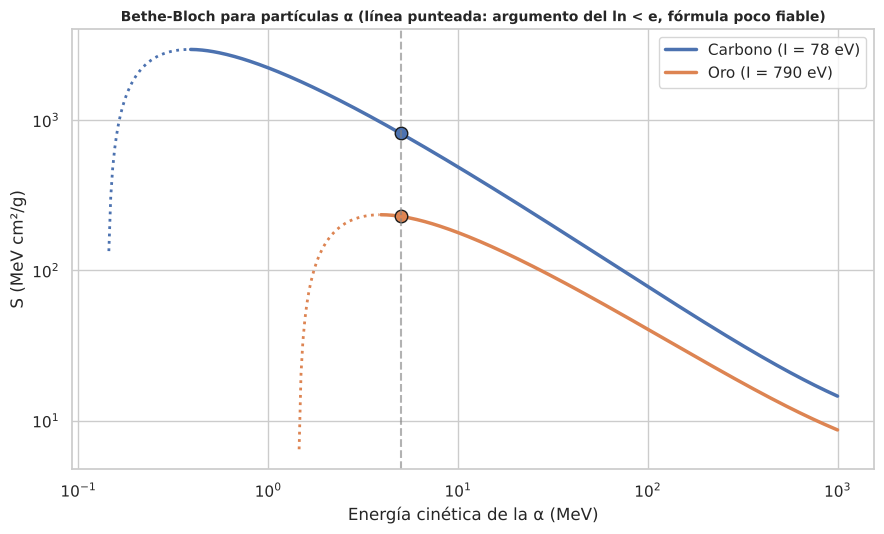

In [5]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
T_alpha = 5.0          # Energía cinética (MeV)
M_alpha = 3727.38      # Masa en reposo de la alfa (MeV)
z = 2                  # Carga de la alfa

materiales_p2 = {
    #          rho (g/cm3), Z,  A (g/mol), I (eV)
    'Carbono': [2.25,        6,  12.01,     78.0],
    'Oro':     [19.3,        79, 197.0,     790.0],
}

# =====================================================================
# 2. FÓRMULA DE BETHE-BLOCH (versión del enunciado)
# =====================================================================
def bethe_bloch_hoja(T, M, z, Z, A, I_eV):
    # Poder de frenado másico (MeV cm²/g) según la fórmula del enunciado
    gamma = 1.0 + T / M
    beta2 = 1.0 - 1.0 / gamma**2
    argumento = 2.0 * me_c2 * 1e6 * beta2 / (I_eV * (1.0 - beta2))
    return K_BB * (Z / A) * z**2 / beta2 * np.log(argumento), beta2, argumento

# =====================================================================
# 3. CÁLCULOS E IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 2)                    ")
print("=====================================================================")
_, beta2_a, _ = bethe_bloch_hoja(T_alpha, M_alpha, z, 1, 1, 1)
print(f"β² de la alfa de {T_alpha} MeV: {beta2_a:.4e}   (β = {np.sqrt(beta2_a):.4f})")
print("-" * 69)
print(f"{'Material':<10} | {'Z/A':>6} | {'arg. ln':>8} | {'ln':>6} | {'S (MeV cm²/g)':>14} | {'dE/dx (MeV/cm)':>14}")
print("-" * 69)
S_p2 = {}
for nombre, (rho, Z, A, I) in materiales_p2.items():
    S, b2, arg = bethe_bloch_hoja(T_alpha, M_alpha, z, Z, A, I)
    S_p2[nombre] = S
    print(f"{nombre:<10} | {Z/A:6.4f} | {arg:8.2f} | {np.log(arg):6.3f} | {S:14.1f} | {rho*S:14.0f}")
print("-" * 69)
print(f"Cociente S_C / S_Au = {S_p2['Carbono']/S_p2['Oro']:.2f}")
S_ref = {'Carbono': 772.0, 'Oro': 233.0}   # valores de referencia (MeV cm²/g)
for nombre in S_p2:
    print(f"{nombre:<8}: Bethe-Bloch = {S_p2[nombre]:6.1f}  |  referencia = {S_ref[nombre]:6.1f}  "
          f"|  diferencia = {100*(S_p2[nombre]-S_ref[nombre])/S_ref[nombre]:+5.1f}%")
print("=====================================================================")

# =====================================================================
# 4. GRÁFICA: S(E) de Bethe-Bloch para alfas en C y Au
# =====================================================================
T_plot = np.logspace(-1, 3, 400)
fig, ax = plt.subplots(figsize=(9, 5.5))
for (nombre, (rho, Z, A, I)), color in zip(materiales_p2.items(), ['#4c72b0', '#dd8452']):
    S, b2, arg = bethe_bloch_hoja(T_plot, M_alpha, z, Z, A, I)
    valido = arg > np.e           # zona donde el logaritmo es "razonablemente" grande
    ax.loglog(T_plot[valido], S[valido], color=color, lw=2.5, label=f'{nombre} (I = {I:.0f} eV)')
    ax.loglog(T_plot[(~valido) & (arg > 1)], S[(~valido) & (arg > 1)], color=color, lw=2, ls=':')
    ax.plot(T_alpha, S_p2[nombre], 'o', color=color, ms=9, mec='k')
ax.axvline(T_alpha, color='gray', ls='--', alpha=0.6)
ax.set_xlabel('Energía cinética de la α (MeV)')
ax.set_ylabel('S (MeV cm²/g)')
ax.set_title('Bethe-Bloch para partículas α (línea punteada: argumento del ln < e, fórmula poco fiable)',
             fontsize=10, fontweight='bold')
ax.legend()
plt.tight_layout(); plt.show()

### **Problema 3**
Un protón de 1 GeV deposita en el aire una energía de 1.96 MeV por g cm⁻². Calcular la energía que deben tener las partículas de carga unidad de la tabla para depositar la misma energía en aire que un protón. Calcular la energía que deposita por unidad de espesor másico una partícula $\alpha$ de 4 GeV.

| Partícula | protón | muón | pión | deuterón | alfa |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Masa/$m_ec^2$** | 1840 | 207 | 273 | 3670 | 7290 |

---

#### **Idea clave: el poder de frenado sólo depende de la velocidad de la partícula**
En la fórmula de Bethe-Bloch,
$$ S = K \frac{Z}{A}\frac{z^2}{\beta^2}\left[\ln\frac{2m_ec^2\beta^2\gamma^2}{I} - \beta^2\right] $$
la partícula incidente sólo aparece a través de su **carga $z$** y de su **velocidad $\beta$** (o, equivalentemente, de $\gamma$ o de $\beta\gamma = p/Mc$). **Su masa no aparece.** Por tanto, en un mismo medio:

* Dos partículas de **igual carga** y **igual velocidad** depositan **la misma energía** por unidad de espesor.
* A igual velocidad, $S \propto z^2$.

#### **1. Velocidad del protón de 1 GeV**
$m_pc^2 = 1840 \times 0.511 = 940.2\text{ MeV}$
$$ \gamma_p = 1 + \frac{T}{m_pc^2} = 1 + \frac{1000}{940.2} = 2.0636, \qquad \beta = 0.8747, \qquad \beta\gamma = 1.805 $$

#### **2. Energía cinética de las demás partículas de carga unidad**
Deben tener el mismo $\gamma$, luego $T = (\gamma - 1)\,Mc^2 = 1.0636\, Mc^2$:

| Partícula | $Mc^2$ (MeV) | $T = (\gamma-1)Mc^2$ (MeV) |
| :--- | :---: | :---: |
| Muón | 105.8 | **112.5** |
| Pión | 139.5 | **148.4** |
| Deuterón | 1875.4 | **1994.6** |

Es decir, todas tienen **la misma energía cinética por unidad de masa** ($T/M$ constante).

#### **3. Partícula $\alpha$ de 4 GeV**
$M_\alpha c^2 = 7290 \times 0.511 = 3725.2\text{ MeV}$:
$$ \gamma_\alpha = 1 + \frac{4000}{3725.2} = 2.0738 \approx \gamma_p $$
¡Prácticamente la misma velocidad que el protón de 1 GeV! (ambos tienen $\approx 1$ GeV por nucleón). Como la $\alpha$ tiene $z = 2$:
$$ S_\alpha \approx z^2\, S_p = 4 \times 1.96 = \mathbf{7.84\text{ MeV cm}^2/\text{g}} $$
La pequeña diferencia de velocidad es irrelevante porque estamos muy cerca del **mínimo de ionización** ($\beta\gamma \approx 3$–$4$), donde $S$ apenas varía con la energía.

> **Comprobación:** la fórmula completa de Bethe-Bloch en aire ($Z/A = 0.4992$, $I = 85.7$ eV) da $S_p(1\text{ GeV}) = 1.964$ MeV cm²/g, en perfecto acuerdo con el dato del enunciado.

In [6]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
T_p = 1000.0           # Energía cinética del protón (MeV)
S_p_dato = 1.96        # MeV cm²/g (dato)
T_alfa = 4000.0        # Energía cinética de la alfa (MeV)

particulas = {         # Masa / me c², carga z
    'protón':   (1840, 1),
    'muón':     (207, 1),
    'pión':     (273, 1),
    'deuterón': (3670, 1),
    'alfa':     (7290, 2),
}

# Bethe-Bloch completa (sin efecto densidad ni correcciones de capa)
aire = dict(ZA=0.49919, I_eV=85.7)

def bethe_bloch(gamma, z, ZA, I_eV):
    beta2 = 1.0 - 1.0 / gamma**2
    return K_BB * ZA * z**2 / beta2 * (np.log(2 * me_c2 * 1e6 * beta2 * gamma**2 / I_eV) - beta2)

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
M_p = particulas['protón'][0] * me_c2
gamma_p = 1.0 + T_p / M_p
beta_p = np.sqrt(1.0 - 1.0 / gamma_p**2)

M_a = particulas['alfa'][0] * me_c2
gamma_a = 1.0 + T_alfa / M_a
S_alfa = particulas['alfa'][1]**2 * S_p_dato

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 3)                    ")
print("=====================================================================")
print(f"Protón de 1 GeV:  M = {M_p:.1f} MeV,  γ = {gamma_p:.4f},  β = {beta_p:.4f},  βγ = {beta_p*gamma_p:.3f}")
print(f"Comprobación Bethe-Bloch (aire): S_p = {bethe_bloch(gamma_p, 1, **aire):.3f} MeV cm²/g (dato: {S_p_dato})")
print("-" * 69)
print(f"{'Partícula':<10} | {'Mc² (MeV)':>10} | {'T necesaria (MeV)':>18} | {'T/M':>8}")
print("-" * 69)
for nombre, (m, zz) in particulas.items():
    if zz != 1:
        continue
    M = m * me_c2
    T = (gamma_p - 1.0) * M
    print(f"{nombre:<10} | {M:10.1f} | {T:18.1f} | {T/M:8.4f}")
print("-" * 69)
print(f"Alfa de 4 GeV: γ = {gamma_a:.4f} (≈ γ_p = {gamma_p:.4f})")
print(f"   -> S_α ≈ z² · S_p = {S_alfa:.2f} MeV cm²/g")
print(f"   -> Bethe-Bloch directa: {bethe_bloch(gamma_a, 2, **aire):.2f} MeV cm²/g")
print("=====================================================================")

                RESULTADOS NUMÉRICOS (PROBLEMA 3)                    
Protón de 1 GeV:  M = 940.2 MeV,  γ = 2.0636,  β = 0.8747,  βγ = 1.805
Comprobación Bethe-Bloch (aire): S_p = 1.964 MeV cm²/g (dato: 1.96)
---------------------------------------------------------------------
Partícula  |  Mc² (MeV) |  T necesaria (MeV) |      T/M
---------------------------------------------------------------------
protón     |      940.2 |             1000.0 |   1.0636
muón       |      105.8 |              112.5 |   1.0636
pión       |      139.5 |              148.4 |   1.0636
deuterón   |     1875.4 |             1994.6 |   1.0636
---------------------------------------------------------------------
Alfa de 4 GeV: γ = 2.0738 (≈ γ_p = 2.0636)
   -> S_α ≈ z² · S_p = 7.84 MeV cm²/g
   -> Bethe-Bloch directa: 7.84 MeV cm²/g


#### **Bonus: Explorador interactivo de la fórmula de Bethe-Bloch**

El siguiente widget representa la fórmula de Bethe-Bloch (sin efecto densidad ni correcciones de capa) para distintas partículas y materiales. Permite elegir la variable del eje horizontal:

* **Energía cinética $T$:** las curvas de las distintas partículas aparecen desplazadas (a igual $T$, la más ligera es más rápida).
* **$\beta\gamma = p/Mc$:** ¡todas las curvas de partículas con $z = 1$ **colapsan en una sola**! La de la $\alpha$ queda multiplicada por $z^2 = 4$.

**Cuestiones:**
1. Elige "Aire" y la variable $\beta\gamma$. ¿Dónde está el **mínimo de ionización**? ¿Cuánto vale $S_{min}$ para partículas de carga unidad?
2. Cambia a la variable $T$. ¿A qué energía cinética tiene su mínimo un muón? ¿Y un protón? Relaciónalo con el resultado del problema.
3. Compara "Agua", "Aluminio" y "Plomo". ¿Por qué el mínimo de ionización (en MeV cm²/g) es menor en materiales pesados?
4. A muy alta energía la curva vuelve a subir (**subida relativista**). En materiales reales esta subida queda muy atenuada por el **efecto densidad** (no incluido aquí).

In [7]:
materiales_bb = {
    #            Z/A,       I (eV)
    'Aire':      (0.49919,  85.7),
    'Agua':      (0.55509,  75.0),
    'Carbono':   (6/12.01,  78.0),
    'Aluminio':  (13/26.98, 166.0),
    'Oro':       (79/197.0, 790.0),
    'Plomo':     (82/207.2, 823.0),
}
colores_part = {'protón': '#4c72b0', 'muón': '#55a868', 'pión': '#8172b3',
                'deuterón': '#937860', 'alfa': '#c44e52'}

def explorador_bethe_bloch(material, variable, particula):
    ZA, I = materiales_bb[material]
    bg = np.logspace(np.log10(0.05), np.log10(2000), 600)
    gamma = np.sqrt(1 + bg**2)

    fig, ax = plt.subplots(figsize=(10, 6))
    for nombre, (m, zz) in particulas.items():
        M = m * me_c2
        S = bethe_bloch(gamma, zz, ZA, I)
        ok = S > 0
        x = bg if variable == 'βγ = p/Mc' else (gamma - 1) * M
        resaltar = (nombre == particula)
        ax.plot(x[ok], S[ok], color=colores_part[nombre], lw=3.5 if resaltar else 1.5,
                alpha=1 if resaltar else 0.55, label=f'{nombre} (z = {zz})')

    # Mínimo de ionización de la partícula seleccionada
    m_sel, z_sel = particulas[particula]
    S_sel = bethe_bloch(gamma, z_sel, ZA, I)
    S_sel[S_sel <= 0] = np.inf
    i_min = np.argmin(S_sel)
    T_min = (gamma[i_min] - 1) * m_sel * me_c2
    x_min = bg[i_min] if variable == 'βγ = p/Mc' else T_min
    ax.plot(x_min, S_sel[i_min], '*', color='gold', ms=18, mec='k', zorder=5,
            label=f'Mínimo ({particula}): {S_sel[i_min]:.2f} MeV cm²/g')

    # Referencia del problema (protón de 1 GeV en aire)
    ax.axhline(1.96, color='gray', ls=':', lw=1.2)
    ax.text(0.06 if variable == 'βγ = p/Mc' else 0.6, 2.1,
            '1.96 MeV cm²/g (protón de 1 GeV en aire)', fontsize=8, color='gray')

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_ylim(1, 2000)
    ax.set_xlabel('βγ = p/Mc' if variable == 'βγ = p/Mc' else 'Energía cinética T (MeV)')
    ax.set_ylabel('S (MeV cm²/g)')
    ax.set_title(f'Bethe-Bloch en {material} (Z/A = {ZA:.3f}, I = {I:.0f} eV)', fontweight='bold')
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout(); plt.show()

    print(f"Mínimo de ionización ({particula} en {material}): S_min = {S_sel[i_min]:.3f} MeV cm²/g "
          f"en βγ ≈ {bg[i_min]:.2f}  (T ≈ {T_min:.0f} MeV)")

interact(explorador_bethe_bloch,
         material=widgets.Dropdown(options=list(materiales_bb), value='Aire', description='Material'),
         variable=widgets.ToggleButtons(options=['βγ = p/Mc', 'Energía cinética T'], value='βγ = p/Mc',
                                        description='Eje X'),
         particula=widgets.Dropdown(options=list(particulas), value='protón', description='Resaltar'));

### **Problema 4**
Un haz fino de rayos $\alpha$ de intensidad $I_0$ y energía $E_0$ (monoenergéticos) incide sobre un medio material. ¿Cuál es la intensidad y el espectro de energía del haz después de haber atravesado un espesor $x$? Resolver el problema suponiendo un haz de rayos $\alpha$ de intensidad inicial $I_0 = 10^5\text{ cm}^{-2}\text{ s}^{-1}$ y energía $E_0 = 4.0$ MeV que atraviesa un espesor de 1 cm de aire (c.n.).

**DATOS:**
* Densidad del aire (c.n.) $\rho = 1.2\times10^{-3}\text{ g cm}^{-3}$.
* Para este rango de energías el poder de frenado se puede expresar aproximadamente como $\dfrac{dE}{dX}\,(\text{MeV cm}^2\text{ g}^{-1}) = -2.25\times10^{3}\,\big(E(\text{MeV})\big)^{-0.696}$.

---

#### **1. Intensidad del haz: diferencia esencial con los fotones**
Una partícula cargada pesada pierde su energía de forma **casi continua**, en un número enorme de colisiones con los electrones del medio, cada una de las cuales le arrebata una fracción minúscula de su energía y apenas la desvía. A diferencia de lo que ocurre con los fotones (que desaparecen del haz en una sola interacción, dando lugar a la atenuación exponencial), **las partículas $\alpha$ no "desaparecen" del haz hasta que se han frenado por completo**.

Por tanto:
$$ I(x) = I_0 \quad \text{para } x < R, \qquad I(x) = 0 \quad \text{para } x > R $$
donde $R$ es el **alcance**. (En la realidad, la transición en $x = R$ no es abrupta sino que se suaviza por las fluctuaciones estadísticas de la pérdida de energía: es el *straggling* en alcance, del orden del 1 % de $R$ para partículas $\alpha$).

#### **2. Espectro de energía**
En la aproximación de frenado continuo, todas las partículas pierden la misma energía, de modo que el haz sigue siendo **monoenergético**, con energía $E(x)$. Su espectro es una delta de Dirac, $\delta\big(E - E(x)\big)$, que en la práctica se ensancha ligeramente por el *straggling* en energía.

#### **3. Cálculo de $E(x)$**
Llamando $X = \rho x$ al espesor másico y escribiendo $\frac{dE}{dX} = -k E^{-n}$ con $k = 2.25\times10^3$ y $n = 0.696$, separamos variables:
$$ E^{n}\, dE = -k\, dX \quad\Longrightarrow\quad \frac{E^{n+1} - E_0^{n+1}}{n+1} = -k X $$
$$ \boxed{E(X) = \left[E_0^{\,n+1} - (n+1)\,k\,X\right]^{\frac{1}{n+1}}} $$

**Sustitución numérica** ($n + 1 = 1.696$, $X = 1.2\times10^{-3}\text{ g cm}^{-2}$):
$$ E_0^{1.696} = 4^{1.696} = 10.50, \qquad (n+1)kX = 1.696 \times 2250 \times 1.2\times10^{-3} = 4.579 $$
$$ E(1\text{ cm}) = (10.50 - 4.58)^{1/1.696} = 5.92^{0.5896} \approx \mathbf{2.85\text{ MeV}} $$

#### **4. Alcance**
Haciendo $E(X) = 0$:
$$ X_R = \frac{E_0^{\,n+1}}{(n+1)\,k} = \frac{10.50}{1.696\times 2250} = 2.75\times10^{-3}\text{ g cm}^{-2} \quad\Rightarrow\quad R = \frac{X_R}{\rho} \approx 2.29\text{ cm} $$

Como $1\text{ cm} < R$, **todas las partículas atraviesan el espesor**:
$$ \mathbf{I(1\text{ cm}) = I_0 = 10^5\text{ cm}^{-2}\text{ s}^{-1}}, \qquad \text{espectro: } \delta(E - 2.85\text{ MeV}) $$

In [8]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
I0 = 1e5           # cm^-2 s^-1
E0_p4 = 4.0        # MeV
x_p4 = 1.0         # cm
rho_aire = 1.2e-3  # g/cm^3
k_p4 = 2.25e3      # MeV cm²/g (coeficiente del poder de frenado)
n_p4 = 0.696       # exponente

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
def energia_alfa(x_cm, E0=E0_p4, k=k_p4, n=n_p4, rho=rho_aire):
    # Energía de la alfa tras recorrer x_cm de aire (0 si se ha frenado)
    base = E0**(n + 1) - (n + 1) * k * rho * np.asarray(x_cm, dtype=float)
    return np.where(base > 0, np.abs(base)**(1.0 / (n + 1)), 0.0)

X_R = E0_p4**(n_p4 + 1) / ((n_p4 + 1) * k_p4)   # g/cm²
R_p4 = X_R / rho_aire                             # cm
E_x = float(energia_alfa(x_p4))
I_x = I0 if x_p4 < R_p4 else 0.0

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 4)                    ")
print("=====================================================================")
print(f"Espesor másico atravesado X = ρx = {rho_aire*x_p4:.2e} g/cm²")
print(f"Energía de las α tras {x_p4} cm de aire:  E = {E_x:.3f} MeV")
print(f"Alcance de las α de {E0_p4} MeV:          X_R = {X_R:.3e} g/cm²  ->  R = {R_p4:.2f} cm")
print(f"Intensidad tras {x_p4} cm de aire:        I = {I_x:.1e} cm⁻² s⁻¹  (= I0, ninguna α se ha frenado)")
print("=====================================================================")

                RESULTADOS NUMÉRICOS (PROBLEMA 4)                    
Espesor másico atravesado X = ρx = 1.20e-03 g/cm²
Energía de las α tras 1.0 cm de aire:  E = 2.853 MeV
Alcance de las α de 4.0 MeV:          X_R = 2.751e-03 g/cm²  ->  R = 2.29 cm
Intensidad tras 1.0 cm de aire:        I = 1.0e+05 cm⁻² s⁻¹  (= I0, ninguna α se ha frenado)


#### **Bonus: Partículas $\alpha$ frente a fotones — intensidad y espectro**

Este simulador muestra cómo evolucionan la energía, la intensidad y el espectro de un haz de $\alpha$ al atravesar aire. Para hacerlo más realista se incluye, de forma aproximada, el **straggling**:

* **En energía:** fórmula de Bohr, $\Omega^2 \approx 0.157\, z^2 \frac{Z}{A}\, X$ (MeV², con $X$ en g/cm²), válida mientras la partícula conserva la mayor parte de su energía.
* **En alcance:** se modela con una distribución gaussiana de anchura $\sigma_R \approx 1.2\,\%\, R$ (valor típico para $\alpha$ en aire).

Para comparar, se dibuja también la intensidad de un haz de **fotones** con un camino libre medio igual al alcance de las $\alpha$.

**Cuestiones:**
1. ¿Por qué la intensidad del haz de $\alpha$ se mantiene constante y luego cae bruscamente, mientras que la de los fotones decae exponencialmente desde el principio?
2. ¿Qué significa físicamente el **alcance medio** (punto donde $I = I_0/2$) y el **alcance extrapolado**?
3. Observa cómo se ensancha el espectro al aumentar $x$. ¿Por qué el ensanchamiento relativo $\Omega/E$ crece rápidamente cerca del final del recorrido?

In [9]:
from scipy.special import erfc

def simulador_haz_alfa(E0_w, x_w):
    X_R_w = E0_w**(n_p4 + 1) / ((n_p4 + 1) * k_p4)
    R_w = X_R_w / rho_aire
    sigma_R = 0.012 * R_w
    x_arr = np.linspace(0, 1.25 * R_w, 600)
    E_arr = energia_alfa(x_arr, E0=E0_w)
    I_alfa = 0.5 * erfc((x_arr - R_w) / (np.sqrt(2) * sigma_R))
    I_foton = np.exp(-x_arr / R_w)

    E_xw = float(energia_alfa(x_w, E0=E0_w))
    I_xw = 0.5 * erfc((x_w - R_w) / (np.sqrt(2) * sigma_R))
    Omega = np.sqrt(0.157 * 2**2 * 0.5 * rho_aire * x_w)   # MeV (straggling de Bohr)

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

    ax = axes[0]
    ax.plot(x_arr, E_arr, color='#4c72b0', lw=2.5, label='E(x)')
    ax2 = ax.twinx()
    dEdx = np.where(E_arr > 0.05, k_p4 * rho_aire * np.maximum(E_arr, 1e-3)**(-n_p4), np.nan)
    ax2.plot(x_arr, dEdx, color='#c44e52', lw=2, ls='--', label='-dE/dx')
    ax2.set_ylabel('-dE/dx (MeV/cm)', color='#c44e52'); ax2.grid(False)
    ax.axvline(x_w, color='gray', ls=':')
    ax.plot(x_w, E_xw, 'o', color='gold', mec='k', ms=10)
    ax.set_xlabel('x (cm de aire)'); ax.set_ylabel('E (MeV)', color='#4c72b0')
    ax.set_title('Energía y pérdida de energía', fontweight='bold')

    ax = axes[1]
    ax.plot(x_arr, I_alfa, color='#c44e52', lw=2.5, label='Partículas α')
    ax.plot(x_arr, I_foton, color='#55a868', lw=2, ls='--', label=f'Fotones (λ = R = {R_w:.2f} cm)')
    ax.axvline(x_w, color='gray', ls=':')
    ax.axvline(R_w, color='k', ls='-.', alpha=0.5)
    ax.text(R_w, 1.02, ' R', fontsize=10)
    ax.set_ylim(0, 1.1)
    ax.set_xlabel('x (cm de aire)'); ax.set_ylabel('I(x) / I₀')
    ax.set_title('Intensidad transmitida', fontweight='bold')
    ax.legend(loc='lower left')

    ax = axes[2]
    if E_xw > 0 and Omega > 0:
        Eg = np.linspace(max(0, E_xw - 6 * Omega), E_xw + 6 * Omega, 400)
        espectro = np.exp(-0.5 * ((Eg - E_xw) / Omega)**2) / (np.sqrt(2 * np.pi) * Omega)
        ax.plot(Eg, espectro, color='#8172b3', lw=2.5)
        ax.fill_between(Eg, espectro, color='#8172b3', alpha=0.2)
        ax.axvline(E_xw, color='k', ls='--', lw=1)
        ax.set_xlim(0, E0_w * 1.05)
        ax.set_title(f'Espectro a x = {x_w:.2f} cm (Ω = {Omega*1e3:.0f} keV)', fontweight='bold')
    elif x_w == 0:
        ax.axvline(E0_w, color='#8172b3', lw=3)
        ax.set_xlim(0, E0_w * 1.05)
        ax.set_title('Espectro incidente: δ(E - E₀)', fontweight='bold')
    else:
        ax.text(0.5, 0.5, 'Las α se han frenado:\nno queda haz', ha='center', va='center',
                transform=ax.transAxes, fontsize=13)
        ax.set_title('Espectro', fontweight='bold')
    ax.set_xlabel('E (MeV)'); ax.set_ylabel('dN/dE (normalizado)')

    plt.tight_layout(); plt.show()
    print(f"Alcance R = {R_w:.2f} cm  |  E(x) = {E_xw:.3f} MeV  |  I(x)/I₀ = {I_xw:.3f}  |  "
          f"Straggling de Bohr Ω = {Omega*1e3:.1f} keV")

interact(simulador_haz_alfa,
         E0_w=widgets.FloatSlider(value=4.0, min=1.0, max=8.0, step=0.1, description='E₀ (MeV)',
                                  continuous_update=False),
         x_w=widgets.FloatSlider(value=1.0, min=0.0, max=8.0, step=0.05, description='x (cm)',
                                 continuous_update=False));

### **Problema 5**
El poder de frenado de protones en agua puede ser descrito de manera aproximada por la siguiente expresión:
$$ -\frac{dE}{dx} = 264 \times E^{-0.77} \quad \text{para } 1 < E < 500; \qquad -\frac{dE}{dx} = 2.22 \quad \text{para } E > 500 $$
en donde la energía $E$ está expresada en MeV y el espesor $x$ en g cm⁻².

**a)** Despreciando el corto alcance de los protones por debajo de 1 MeV, obtener una expresión analítica $R(E)$ que describa el alcance de los protones en agua en función de su energía.

**b)** Hallar el alcance para $E = 10$ MeV y $E = 2.0$ GeV.

---

#### **a) Expresión analítica del alcance $R(E)$**
En la aproximación de frenado continuo (CSDA):
$$ R(E) = \int_0^{E} \frac{dE'}{-dE'/dx} \approx \int_1^{E} \frac{dE'}{S(E')} $$
(despreciamos el alcance por debajo de 1 MeV, que es de sólo $\sim 2\times10^{-3}$ g/cm²).

**Tramo 1: $1 < E \le 500$ MeV.** Con $S = a E^{-b}$, $a = 264$, $b = 0.77$:
$$ R(E) = \frac{1}{a}\int_1^{E} E'^{\,b}\, dE' = \frac{E^{\,b+1} - 1}{a\,(b+1)} = \boxed{\frac{E^{1.77} - 1}{467.3}\ \text{g cm}^{-2}} $$

**Tramo 2: $E > 500$ MeV.** El poder de frenado es constante, $S = \alpha = 2.22$:
$$ R(E) = R(500) + \frac{E - 500}{2.22} = \boxed{128.1 + \frac{E - 500}{2.22}\ \text{g cm}^{-2}} $$
con $R(500) = (500^{1.77} - 1)/467.3 = 128.1$ g cm⁻².

> **Comprobación de continuidad:** a 500 MeV la ley de potencias da $264 \times 500^{-0.77} = 2.205$ MeV cm²/g, muy próximo a 2.22: las dos expresiones empalman bien.

#### **b) Valores numéricos**
* **$E = 10$ MeV** (primer tramo):
$$ R(10) = \frac{10^{1.77} - 1}{467.3} = \frac{58.88 - 1}{467.3} \approx \mathbf{0.124\text{ g cm}^{-2}} \;\Rightarrow\; 1.24\text{ mm de agua} $$
* **$E = 2.0$ GeV** (segundo tramo):
$$ R(2000) = 128.1 + \frac{2000 - 500}{2.22} = 128.1 + 675.7 \approx \mathbf{804\text{ g cm}^{-2}} \;\Rightarrow\; 8.04\text{ m de agua} $$

En la celda de cálculo comparamos además estas expresiones con la integración numérica de los datos tabulados de PSTAR (NIST) para protones en agua (los mismos datos del Problema 11).

                RESULTADOS NUMÉRICOS (PROBLEMA 5)                    
S(500 MeV) por la ley de potencias: 2.205 MeV cm²/g  (vs. 2.22)
R(500 MeV) = 128.1 g/cm²
---------------------------------------------------------------------
 E (MeV) |  R analítico (g/cm²) |  R PSTAR num. (g/cm²) | Dif. (%)
---------------------------------------------------------------------
      10 |               0.1239 |                0.1206 |     2.69
     100 |                7.418 |                 7.718 |    -3.89
     250 |                37.56 |                 37.94 |    -0.99
    2000 |                803.8 |                 804.3 |    -0.06


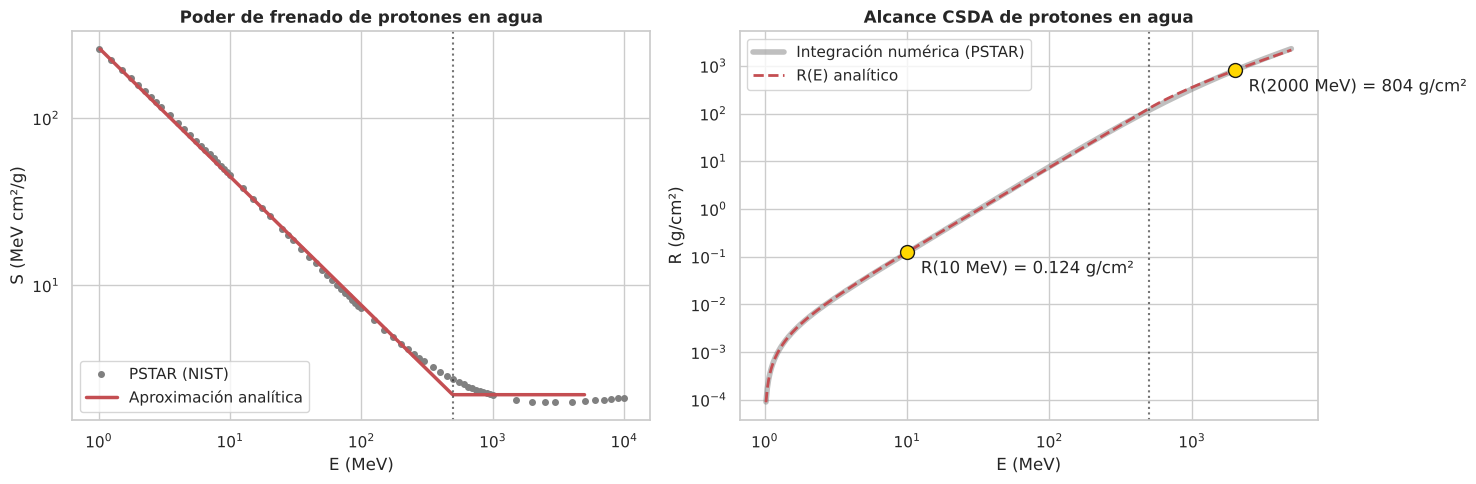

In [10]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
a_p, b_p = 264.0, 0.77      # S = a E^-b   (1 < E < 500 MeV)
alpha_p, Et_p = 2.22, 500.0 # S = alpha    (E > 500 MeV)

def S_protones_p5(E):
    E = np.asarray(E, dtype=float)
    return np.where(E <= Et_p, a_p * E**(-b_p), alpha_p)

def R_protones_p5(E):
    # Alcance analítico en agua (g/cm²), despreciando E < 1 MeV
    E = np.asarray(E, dtype=float)
    R_bajo = (np.minimum(E, Et_p)**(b_p + 1) - 1.0) / (a_p * (b_p + 1))
    R_alto = np.where(E > Et_p, (E - Et_p) / alpha_p, 0.0)
    return R_bajo + R_alto

# Datos PSTAR (NIST) de protones en agua (ver Problema 11)
pstar = pd.read_csv('data/datos_problema_2-11.csv', comment='#')
E_pstar, S_pstar = pstar['E_MeV'].values, pstar['S'].values

# =====================================================================
# 2. CÁLCULOS E IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 5)                    ")
print("=====================================================================")
print(f"S(500 MeV) por la ley de potencias: {a_p*500**-b_p:.3f} MeV cm²/g  (vs. 2.22)")
print(f"R(500 MeV) = {float(R_protones_p5(500)):.1f} g/cm²")
print("-" * 69)
print(f"{'E (MeV)':>8} | {'R analítico (g/cm²)':>20} | {'R PSTAR num. (g/cm²)':>21} | {'Dif. (%)':>8}")
print("-" * 69)
for E in [10.0, 100.0, 250.0, 2000.0]:
    Ra = float(R_protones_p5(E))
    Rn = alcance_csda(E_pstar, S_pstar, 1.0, E)
    print(f"{E:8.0f} | {Ra:20.4g} | {Rn:21.4g} | {100*(Ra-Rn)/Rn:8.2f}")
print("=====================================================================")

# =====================================================================
# 3. GRÁFICAS
# =====================================================================
E_plot = np.logspace(0.01, np.log10(5000), 400)
R_num = np.array([alcance_csda(E_pstar, S_pstar, 1.0, E, n=1500) for E in E_plot])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.loglog(E_pstar, S_pstar, 'o', color='gray', ms=4, label='PSTAR (NIST)')
ax.loglog(E_plot, S_protones_p5(E_plot), color='#c44e52', lw=2.5, label='Aproximación analítica')
ax.axvline(Et_p, color='k', ls=':', alpha=0.6)
ax.set_xlabel('E (MeV)'); ax.set_ylabel('S (MeV cm²/g)')
ax.set_title('Poder de frenado de protones en agua', fontweight='bold')
ax.legend()

ax = axes[1]
ax.loglog(E_plot, R_num, color='gray', lw=4, alpha=0.5, label='Integración numérica (PSTAR)')
ax.loglog(E_plot, R_protones_p5(E_plot), color='#c44e52', lw=2, ls='--', label='R(E) analítico')
for E in [10, 2000]:
    ax.plot(E, R_protones_p5(E), 'o', color='gold', mec='k', ms=10)
    ax.annotate(f'R({E} MeV) = {float(R_protones_p5(E)):.3g} g/cm²', xy=(E, R_protones_p5(E)),
                xytext=(10, -15), textcoords='offset points')
ax.axvline(Et_p, color='k', ls=':', alpha=0.6)
ax.set_xlabel('E (MeV)'); ax.set_ylabel('R (g/cm²)')
ax.set_title('Alcance CSDA de protones en agua', fontweight='bold')
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

### **Problema 6**
El poder de frenado colisional para electrones moviéndose en agua ($\rho = 1.00\text{ g cm}^{-3}$) a la energía crítica ($E_c = 91$ MeV) es de $(dE/dx)_{col} = 2.20\text{ MeV cm}^2\text{ g}^{-1}$. Vamos a suponer que por encima de esta energía el poder de frenado colisional es constante y el radiativo es proporcional a la energía.

**a)** Hallar la energía perdida por colisiones y por emisión de radiación de un electrón con la energía crítica al atravesar 1.00 µm de agua. Repetir el cálculo para un electrón de 1000 MeV.

**b)** Sabiendo que el recorrido en agua de un electrón con energía crítica es de 30.4 cm, hallar el recorrido total de un electrón de 1000 MeV.

**c)** Sabiendo que el valor del *radiation yield* $B$ a la energía crítica es $B_c = 0.298$, hallar la energía que deja en agua (en forma de excitaciones e ionizaciones atómicas) un electrón de 1000 MeV.
$$ B = \frac{1}{E_0}\int_0^{E_0} \frac{(dE/dx)_{rad}}{(dE/dx)_{tot}}\, dE $$

---

#### **Modelo de pérdidas por encima de $E_c$**
* Colisional: $S_{col} = a = 2.20$ MeV cm²/g (constante).
* Radiativo: $S_{rad} = b\,E$. Por definición de **energía crítica**, $S_{rad}(E_c) = S_{col}(E_c)$, de donde
$$ b = \frac{a}{E_c} = \frac{2.20}{91} = 2.418\times10^{-2}\text{ cm}^2/\text{g} \quad\Longrightarrow\quad X_0 = \frac{1}{b} = 41.4\text{ g cm}^{-2} $$
($X_0$ es la longitud de radiación del modelo; el valor tabulado para el agua es 36.1 g/cm²).

#### **a) Pérdidas en 1 µm de agua**
$\Delta x = 1.00\ \mu\text{m} = 10^{-4}$ cm $\Rightarrow$ $\Delta X = \rho\,\Delta x = 10^{-4}$ g/cm². Este espesor es tan pequeño que la energía apenas cambia y podemos usar $S$ constante:

| Electrón | $\Delta E_{col} = a\,\Delta X$ | $\Delta E_{rad} = bE\,\Delta X$ |
| :--- | :---: | :---: |
| $E = E_c = 91$ MeV | $2.2\times10^{-4}$ MeV = **220 eV** | **220 eV** (igual, por definición de $E_c$) |
| $E = 1000$ MeV | **220 eV** | $2.418\times10^{-2}\times1000\times10^{-4}$ MeV = **2.42 keV** |

A 1000 MeV las pérdidas radiativas son $1000/91 \approx 11$ veces mayores que las colisionales.

#### **b) Recorrido total de un electrón de 1000 MeV**
Por encima de $E_c$:
$$ \frac{dE}{dX} = -(a + bE) \quad\Longrightarrow\quad \Delta X = \int_{E_c}^{E_0} \frac{dE}{a + bE} = \frac{1}{b}\ln\frac{a + bE_0}{a + bE_c} = X_0 \ln\frac{E_c + E_0}{2E_c} $$
$$ \Delta X = 41.36 \times \ln\frac{91 + 1000}{182} = 41.36 \times \ln(5.995) = 41.36 \times 1.791 \approx 74.1\text{ g cm}^{-2} $$
El recorrido total es este tramo más el recorrido a partir de la energía crítica:
$$ R(1000\text{ MeV}) = 74.1 + 30.4 \approx \mathbf{104.5\text{ cm}} $$

#### **c) Energía depositada por un electrón de 1000 MeV**
La energía que el electrón pierde en colisiones (y queda en el medio como excitaciones e ionizaciones) se divide en dos tramos:

* **De $E_0$ a $E_c$:** como $S_{col}$ es constante, $E_{D,1} = a\,\Delta X = 2.20 \times 74.08 = 163.0$ MeV.
* **De $E_c$ a 0:** por definición del *radiation yield*, un electrón de energía $E_c$ radia $B_c E_c$ y deposita $E_{D,2} = (1 - B_c)\,E_c = 0.702 \times 91 = 63.9$ MeV.

$$ E_D(1000\text{ MeV}) = 163.0 + 63.9 \approx \mathbf{226.8\text{ MeV}} $$
Es decir, sólo un 23 % de la energía queda depositada localmente; el resto ($\approx 773$ MeV) se emite como radiación de frenado (fotones), lo que corresponde a $B(1000\text{ MeV}) \approx 0.773$.

                RESULTADOS NUMÉRICOS (PROBLEMA 6)                    
b = a/Ec = 2.4176e-02 cm²/g   ->   X0 = 1/b = 41.36 g/cm²
---------------------------------------------------------------------
a) Pérdidas en 1 µm de agua:
   E =     91 MeV:  colisión =   220.0 eV   radiación =   220.0 eV
   E =   1000 MeV:  colisión =   220.0 eV   radiación =  2417.6 eV
---------------------------------------------------------------------
b) Tramo Ec -> 1000 MeV: ΔX = 74.08 g/cm²
   Recorrido total R(1000 MeV) = 104.5 cm
---------------------------------------------------------------------
c) Energía depositada  1000 MeV -> Ec: 163.0 MeV
   Energía depositada  Ec -> 0:        63.9 MeV
   TOTAL depositado:                   226.8 MeV   (B(1000 MeV) = 0.773)


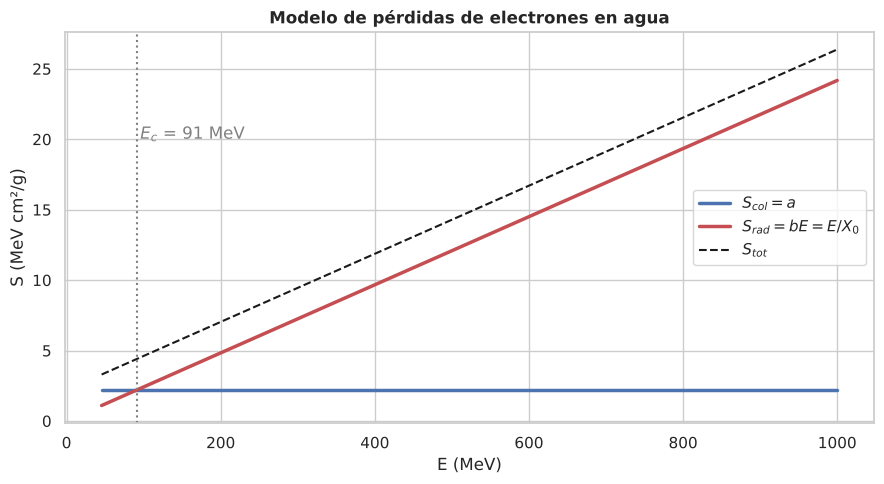

In [11]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
rho_agua = 1.00     # g/cm^3
Ec_p6 = 91.0        # MeV
a_p6 = 2.20         # MeV cm²/g  (colisional, constante)
R_Ec_p6 = 30.4      # cm (recorrido a la energía crítica)
Bc_p6 = 0.298       # radiation yield a Ec
dx_p6 = 1.0e-4      # cm (1 µm)

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
b_p6 = a_p6 / Ec_p6          # cm²/g
X0_p6 = 1.0 / b_p6           # g/cm²
dX = rho_agua * dx_p6        # g/cm²

perdidas = {E: (a_p6 * dX, b_p6 * E * dX) for E in [Ec_p6, 1000.0]}

E0_p6 = 1000.0
DX_p6 = X0_p6 * np.log((a_p6 + b_p6 * E0_p6) / (a_p6 + b_p6 * Ec_p6))   # g/cm²
R_1000 = DX_p6 / rho_agua + R_Ec_p6
ED_tramo1 = a_p6 * DX_p6
ED_tramo2 = (1.0 - Bc_p6) * Ec_p6
ED_total = ED_tramo1 + ED_tramo2
B_1000 = 1.0 - ED_total / E0_p6

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 6)                    ")
print("=====================================================================")
print(f"b = a/Ec = {b_p6:.4e} cm²/g   ->   X0 = 1/b = {X0_p6:.2f} g/cm²")
print("-" * 69)
print("a) Pérdidas en 1 µm de agua:")
for E, (dEc, dEr) in perdidas.items():
    print(f"   E = {E:6.0f} MeV:  colisión = {dEc*1e6:7.1f} eV   radiación = {dEr*1e6:7.1f} eV")
print("-" * 69)
print(f"b) Tramo Ec -> 1000 MeV: ΔX = {DX_p6:.2f} g/cm²")
print(f"   Recorrido total R(1000 MeV) = {R_1000:.1f} cm")
print("-" * 69)
print(f"c) Energía depositada  1000 MeV -> Ec: {ED_tramo1:.1f} MeV")
print(f"   Energía depositada  Ec -> 0:        {ED_tramo2:.1f} MeV")
print(f"   TOTAL depositado:                   {ED_total:.1f} MeV   (B(1000 MeV) = {B_1000:.3f})")
print("=====================================================================")

# Gráfica del modelo de pérdidas
E_m = np.linspace(Ec_p6 * 0.5, 1000, 400)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(E_m, a_p6 * np.ones_like(E_m), color='#4c72b0', lw=2.5, label=r'$S_{col} = a$')
ax.plot(E_m, b_p6 * E_m, color='#c44e52', lw=2.5, label=r'$S_{rad} = bE = E/X_0$')
ax.plot(E_m, a_p6 + b_p6 * E_m, color='k', lw=1.5, ls='--', label=r'$S_{tot}$')
ax.axvline(Ec_p6, color='gray', ls=':')
ax.text(Ec_p6 * 1.05, 20, r'$E_c$ = 91 MeV', color='gray')
ax.set_xlabel('E (MeV)'); ax.set_ylabel('S (MeV cm²/g)')
ax.set_title('Modelo de pérdidas de electrones en agua', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

### **Problema 7**
Empleando los datos del *radiation yield* $B$ y del alcance $R$ para electrones en agua (ver tabla adjunta), hallar la energía radiada por un electrón de 100 MeV en agua hasta pararse. Hallar la energía depositada en el agua y el camino recorrido por el electrón para reducir su energía de 100 a 10 MeV y de 10 a 1 MeV.

| $E$ (MeV) | 1 | 10 | 100 |
| :--- | :---: | :---: | :---: |
| $R$ (g cm⁻²) | 0.430 | 4.88 | 32.5 |
| $B$ | 0.0049 | 0.0416 | 0.317 |

---

#### **Interpretación de $B$ y $R$**
* El *radiation yield* $B(E_0)$ es la **fracción de la energía inicial** $E_0$ que un electrón emite como radiación de frenado **hasta pararse**. Por tanto:
$$ E_{rad}(E_0) = B(E_0)\,E_0, \qquad E_{D}(E_0) = \big(1 - B(E_0)\big)\,E_0 $$
* El alcance (CSDA) $R(E_0)$ es el camino total recorrido hasta pararse.

Para un tramo intermedio $E_1 \to E_2$ basta restar: lo que ocurre entre $E_1$ y $E_2$ es lo que ocurre desde $E_1$ hasta pararse menos lo que ocurre desde $E_2$ hasta pararse.

#### **1. Energía radiada por un electrón de 100 MeV hasta pararse**
$$ E_{rad} = B(100)\times100 = 0.317 \times 100 = \mathbf{31.7\text{ MeV}} $$

#### **2. Tramo 100 → 10 MeV**
$$ E_D = (1-0.317)\times100 - (1-0.0416)\times10 = 68.30 - 9.584 = \mathbf{58.7\text{ MeV}} $$
$$ \Delta X = R(100) - R(10) = 32.5 - 4.88 = \mathbf{27.6\text{ g cm}^{-2}} \;(27.6\text{ cm de agua}) $$
(En este tramo se radian $90 - 58.7 = 31.3$ MeV.)

#### **3. Tramo 10 → 1 MeV**
$$ E_D = (1-0.0416)\times10 - (1-0.0049)\times1 = 9.584 - 0.995 = \mathbf{8.59\text{ MeV}} $$
$$ \Delta X = R(10) - R(1) = 4.88 - 0.430 = \mathbf{4.45\text{ g cm}^{-2}} \;(4.45\text{ cm de agua}) $$
(En este tramo sólo se radian $9 - 8.59 = 0.41$ MeV.)

> **Observación:** prácticamente toda la radiación se emite en el tramo de alta energía, donde el electrón pierde energía muy deprisa ($\sim 3.3$ MeV/cm). Por debajo de 10 MeV las pérdidas son casi exclusivamente colisionales ($\approx 2$ MeV/cm).

                RESULTADOS NUMÉRICOS (PROBLEMA 7)                    
Energía radiada por un e- de 100 MeV hasta pararse: 31.7 MeV
Energía depositada por un e- de 100 MeV hasta pararse: 68.3 MeV
---------------------------------------------------------------------
Tramo            |  E depositada |  E radiada |         Camino |    <dE/dx>
---------------------------------------------------------------------
  100 ->   10 MeV |     58.72 MeV |  31.28 MeV |   27.62 g/cm² |  3.26 MeV/cm
   10 ->    1 MeV |      8.59 MeV |   0.41 MeV |    4.45 g/cm² |  2.02 MeV/cm


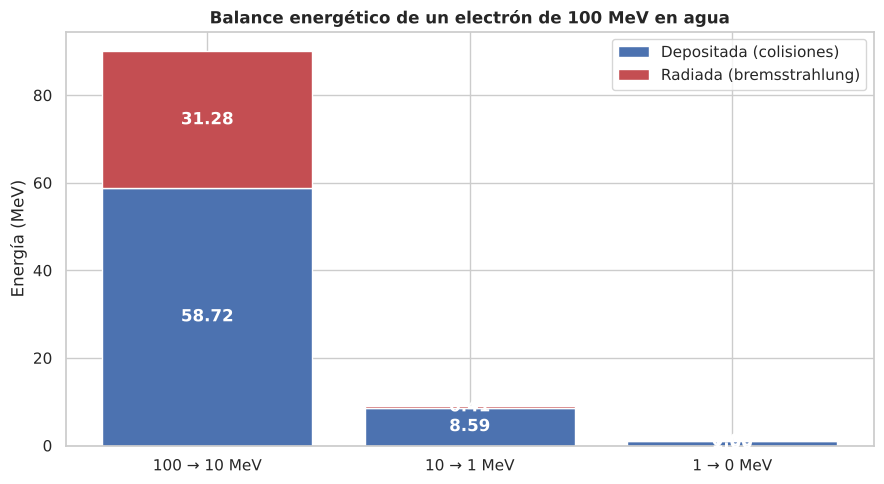

In [12]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
tabla_p7 = pd.DataFrame({'E': [1.0, 10.0, 100.0],
                         'R': [0.430, 4.88, 32.5],
                         'B': [0.0049, 0.0416, 0.317]}).set_index('E')

def E_dep_total(E):   # energía depositada hasta pararse
    return (1.0 - tabla_p7.loc[E, 'B']) * E

def E_rad_total(E):   # energía radiada hasta pararse
    return tabla_p7.loc[E, 'B'] * E

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
tramos = [(100.0, 10.0), (10.0, 1.0)]
resultados_p7 = []
for E1, E2 in tramos:
    ED = E_dep_total(E1) - E_dep_total(E2)
    Erad = E_rad_total(E1) - E_rad_total(E2)
    dX = tabla_p7.loc[E1, 'R'] - tabla_p7.loc[E2, 'R']
    resultados_p7.append((E1, E2, ED, Erad, dX))

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 7)                    ")
print("=====================================================================")
print(f"Energía radiada por un e- de 100 MeV hasta pararse: {E_rad_total(100.0):.1f} MeV")
print(f"Energía depositada por un e- de 100 MeV hasta pararse: {E_dep_total(100.0):.1f} MeV")
print("-" * 69)
print(f"{'Tramo':<16} | {'E depositada':>13} | {'E radiada':>10} | {'Camino':>14} | {'<dE/dx>':>10}")
print("-" * 69)
for E1, E2, ED, Erad, dX in resultados_p7:
    print(f"{E1:5.0f} -> {E2:4.0f} MeV | {ED:9.2f} MeV | {Erad:6.2f} MeV | {dX:7.2f} g/cm² | "
          f"{(E1-E2)/dX:5.2f} MeV/cm")
print("=====================================================================")

# Gráfica: balance energético por tramos
fig, ax = plt.subplots(figsize=(9, 5))
etiquetas = [f'{E1:.0f} → {E2:.0f} MeV' for E1, E2, *_ in resultados_p7] + ['1 → 0 MeV']
dep = [r[2] for r in resultados_p7] + [E_dep_total(1.0)]
rad = [r[3] for r in resultados_p7] + [E_rad_total(1.0)]
b1 = ax.bar(etiquetas, dep, color='#4c72b0', label='Depositada (colisiones)')
b2 = ax.bar(etiquetas, rad, bottom=dep, color='#c44e52', label='Radiada (bremsstrahlung)')
ax.bar_label(b1, fmt='%.2f', label_type='center', color='white', fontweight='bold')
ax.bar_label(b2, fmt='%.2f', label_type='center', color='white', fontweight='bold')
ax.set_ylabel('Energía (MeV)')
ax.set_title('Balance energético de un electrón de 100 MeV en agua', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

### **Problema 8**
Los poderes de frenado colisional y radiativo de electrones con energía superior a la energía crítica obedecen a las siguientes expresiones:
$$ \left(\frac{dE}{dx}\right)_{col} = a; \qquad \left(\frac{dE}{dx}\right)_{rad} = b\times E $$

**a)** Expresar el valor de las constantes $a$ y $b$ en función de la energía crítica $E_c$ y de la longitud de radiación $X$.

**b)** Un electrón con energía inicial $E_0 > E_c$ recorre un camino $\Delta x$ hasta que su energía es igual a $E_c$ y en ese recorrido deposita una energía $E_D$. Demostrar que
$$ \frac{\Delta x}{X} = \frac{E_D}{E_c} = \ln\left(\frac{E_c + E_0}{2E_c}\right) $$

---

#### **a) Constantes $a$ y $b$**
* **Longitud de radiación:** es la distancia en la que, por pérdidas radiativas, la energía de un electrón de alta energía se reduce en un factor $e$:
$$ \left(\frac{dE}{dx}\right)_{rad} = \frac{E}{X} \quad\Longrightarrow\quad \boxed{b = \frac{1}{X}} $$
* **Energía crítica:** es aquella a la que las pérdidas colisionales y radiativas son iguales:
$$ a = b\,E_c \quad\Longrightarrow\quad \boxed{a = \frac{E_c}{X}} $$

#### **b) Camino recorrido y energía depositada hasta $E_c$**
La pérdida total de energía es:
$$ -\frac{dE}{dx} = a + bE = \frac{E_c + E}{X} $$
Separando variables e integrando desde $E_0$ hasta $E_c$:
$$ \Delta x = \int_{E_c}^{E_0} \frac{X\, dE}{E_c + E} = X \ln\frac{E_c + E_0}{E_c + E_c} \quad\Longrightarrow\quad \frac{\Delta x}{X} = \ln\left(\frac{E_c + E_0}{2E_c}\right) $$

La energía **depositada** es la perdida por colisiones. Como $(dE/dx)_{col} = a$ es constante:
$$ E_D = a\,\Delta x = \frac{E_c}{X}\,\Delta x \quad\Longrightarrow\quad \frac{E_D}{E_c} = \frac{\Delta x}{X} \qquad \blacksquare $$

> **Consecuencias interesantes:**
> * El camino recorrido (y la energía depositada) crece sólo **logarítmicamente** con $E_0$: un electrón de 10 GeV en agua no recorre 10 veces más que uno de 1 GeV, sino apenas $\sim 2.3\,X$ más.
> * La fracción de la energía perdida que se deposita, $E_D/(E_0 - E_c)$, tiende a cero a muy altas energías: casi toda la energía se va en forma de fotones de *bremsstrahlung* (que a su vez generan pares... ¡una **cascada electromagnética**!).

A continuación se verifica simbólicamente la demostración con `sympy`.

In [13]:
import sympy as sp

E, E0s, Ecs, Xs = sp.symbols('E E_0 E_c X', positive=True)

a_sym = Ecs / Xs          # (dE/dx)_col
b_sym = 1 / Xs            # (dE/dx)_rad = b E

# Comprobación de la definición de energía crítica: a = b·Ec
print("¿a = b·Ec?  ->", sp.simplify(a_sym - b_sym * Ecs) == 0)

# Camino recorrido entre E0 y Ec
dx_sym = sp.integrate(1 / (a_sym + b_sym * E), (E, Ecs, E0s))
dx_sym = sp.simplify(sp.logcombine(dx_sym, force=True))
print("\nΔx =")
display(dx_sym)

# Energía depositada (sólo pérdidas colisionales)
ED_sym = sp.simplify(a_sym * dx_sym)
print("E_D =")
display(ED_sym)

print("¿Δx/X = E_D/Ec?  ->", sp.simplify(dx_sym / Xs - ED_sym / Ecs) == 0)
print("¿Δx/X = ln((Ec+E0)/(2Ec))?  ->",
      sp.simplify(sp.expand_log(dx_sym / Xs - sp.log((Ecs + E0s) / (2 * Ecs)), force=True)) == 0)

¿a = b·Ec?  -> True



Δx =


log((E_0 + E_c)**X/(2*E_c)**X)

E_D =


log(((E_0 + E_c)/(2*E_c))**E_c)

¿Δx/X = E_D/Ec?  -> True
¿Δx/X = ln((Ec+E0)/(2Ec))?  -> True


#### **Bonus: Simulador de la pérdida de energía de electrones de alta energía**

El modelo $S_{col} = E_c/X_0$, $S_{rad} = E/X_0$ describe con una sola pareja de parámetros ($E_c$, $X_0$) el comportamiento de los electrones de alta energía en cualquier medio. Este simulador integra $E(x)$ y separa la energía perdida en **depositada** (colisiones) y **radiada** (*bremsstrahlung*) a lo largo del recorrido hasta $E_c$. Incluye "presets" con los parámetros de los Problemas 6 (agua), 12 (aire) y 13.

**Cuestiones:**
1. Comprueba que, al representar frente a $x/X_0$ y $E/E_c$, todos los medios dan **exactamente las mismas curvas** (el modelo es *universal*).
2. ¿Qué fracción de la energía inicial se deposita antes de llegar a $E_c$ para $E_0 = 10\,E_c$? ¿Y para $E_0 = 1000\,E_c$?
3. ¿Cuánto camino adicional (en unidades de $X_0$) recorre un electrón si multiplicamos su energía por 10?

In [14]:
presets_e = {
    'Agua (Problema 6)':      (91.0, 41.36, 1.00),
    'Aire (Problema 12)':     (88.97, 36.76, 1.20e-3),
    'Medio del Problema 13':  (90.44, 39.84, 1.00),
}

def simulador_electron_alta_energia(medio, E0_sobre_Ec):
    Ec, X0, rho = presets_e[medio]
    E0 = E0_sobre_Ec * Ec
    a, b = Ec / X0, 1.0 / X0

    DX = X0 * np.log((Ec + E0) / (2 * Ec))       # g/cm²
    X_arr = np.linspace(0, DX, 500)
    E_arr = (Ec + E0) * np.exp(-X_arr / X0) - Ec  # solución de dE/dX = -(Ec + E)/X0
    E_dep = a * X_arr                              # depositada acumulada
    E_rad = (E0 - E_arr) - E_dep                   # radiada acumulada

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    ax = axes[0]
    ax.plot(X_arr / X0, E_arr / Ec, color='k', lw=2.5, label='E(x)/Ec')
    ax.axhline(1, color='gray', ls=':')
    ax.set_xlabel('x / X₀'); ax.set_ylabel('E / Ec')
    ax.set_yscale('log')
    ax.set_title(f'Energía del electrón (E₀ = {E0:.0f} MeV)', fontweight='bold')
    ax.legend()

    ax = axes[1]
    ax.stackplot(X_arr / X0, E_dep, E_rad, colors=['#4c72b0', '#c44e52'], alpha=0.8,
                 labels=['Depositada (colisiones)', 'Radiada (bremsstrahlung)'])
    ax.set_xlabel('x / X₀'); ax.set_ylabel('Energía perdida acumulada (MeV)')
    ax.set_title('Reparto de la energía perdida hasta Ec', fontweight='bold')
    ax.legend(loc='upper left')
    plt.tight_layout(); plt.show()

    unidades = 'm' if rho < 0.01 else 'cm'
    factor = 1 / rho / 100 if rho < 0.01 else 1 / rho
    print(f"Medio: {medio}  |  Ec = {Ec:.1f} MeV, X0 = {X0:.2f} g/cm²")
    print(f"Δx/X0 = ln((Ec+E0)/2Ec) = {DX/X0:.3f}   ->   Δx = {DX:.1f} g/cm² = {DX*factor:.1f} {unidades}")
    print(f"Energía depositada hasta Ec: E_D = {E_dep[-1]:.1f} MeV  ({100*E_dep[-1]/(E0-Ec):.1f}% de lo perdido)")
    print(f"Energía radiada hasta Ec:    {E_rad[-1]:.1f} MeV  ({100*E_rad[-1]/(E0-Ec):.1f}% de lo perdido)")

interact(simulador_electron_alta_energia,
         medio=widgets.Dropdown(options=list(presets_e), value='Agua (Problema 6)', description='Medio'),
         E0_sobre_Ec=widgets.FloatLogSlider(value=1000/91, base=10, min=0.05, max=3, step=0.01,
                                            description='E₀/Ec', continuous_update=False));

### **Problema 9**
Empleando los datos de poder de frenado colisional $S_{col}$ y radiativo $S_{rad}$ de electrones en aire (ver datos en el CV) resolver las siguientes cuestiones:

* Representar gráficamente $S_{col}$ y $S_{rad}$ frente a la energía $E$.
* Calcular el recorrido $R$ de un electrón de 700 MeV hasta pararse.
* Hallar el *bremsstrahlung yield* para 700 MeV. ¿Cuánta energía deposita un electrón de 700 MeV en ese medio?

*(Los datos, procedentes de la base de datos ESTAR del NIST, se encuentran en `data/datos_problema_2-9.csv`: energía cinética entre 10 keV y 1 GeV.)*

---

#### **1. Representación de $S_{col}$ y $S_{rad}$**
En la gráfica (celda siguiente) se observa:
* $S_{col}$ disminuye rápidamente a baja energía ($\propto 1/\beta^2$), pasa por un **mínimo** en torno a 1–1.5 MeV ($\approx 1.65$ MeV cm²/g) y después crece muy lentamente (subida relativista logarítmica).
* $S_{rad}$ es prácticamente constante a baja energía y crece de forma casi **proporcional a $E$** a alta energía.
* Ambas curvas se cruzan en la **energía crítica**, $E_c \approx 100$ MeV para el aire (definición de cruce de curvas).

#### **2. Recorrido (alcance CSDA) de un electrón de 700 MeV**
$$ R(E_0) = \int_0^{E_0} \frac{dE}{S_{col}(E) + S_{rad}(E)} $$
Integrando numéricamente la tabla (interpolación log-log) desde 10 keV (el recorrido por debajo de 10 keV es despreciable, $\sim 3\times10^{-4}$ g/cm²):
$$ R(700\text{ MeV}) \approx \mathbf{86.2\text{ g cm}^{-2}} $$
que, con $\rho_{aire} = 1.20\times10^{-3}$ g/cm³, equivale a $\approx \mathbf{718\text{ m}}$ de aire.

#### **3. *Bremsstrahlung yield* y energía depositada**
$$ B(E_0) = \frac{1}{E_0}\int_0^{E_0}\frac{S_{rad}(E)}{S_{col}(E) + S_{rad}(E)}\,dE $$
Numéricamente: $B(700\text{ MeV}) \approx \mathbf{0.702}$. La energía que el electrón deposita en el medio (por colisiones) es la que no radia:
$$ E_D = (1 - B)\,E_0 = 0.298 \times 700 \approx \mathbf{208\text{ MeV}} $$
Es decir, el 70 % de la energía se emite como fotones de frenado, que en general escapan de la zona donde se ha movido el electrón.

,E_MeV,S_col,S_rad
0,0.0100,19.75,0.003897
1,0.0125,16.63,0.003921
2,0.0150,14.44,0.003937
3,0.0175,12.82,0.003946
4,0.0200,11.57,0.003954


                RESULTADOS NUMÉRICOS (PROBLEMA 9)                    
Mínimo de S_col: 1.655 MeV cm²/g a E = 1.25 MeV
Energía crítica (S_col = S_rad): Ec ≈ 100.5 MeV
---------------------------------------------------------------------
Recorrido CSDA de un e- de 700 MeV: R = 86.19 g/cm²  ->  718 m de aire
Bremsstrahlung yield B(700 MeV) = 0.702
Energía radiada:    491.6 MeV
Energía depositada: 208.4 MeV


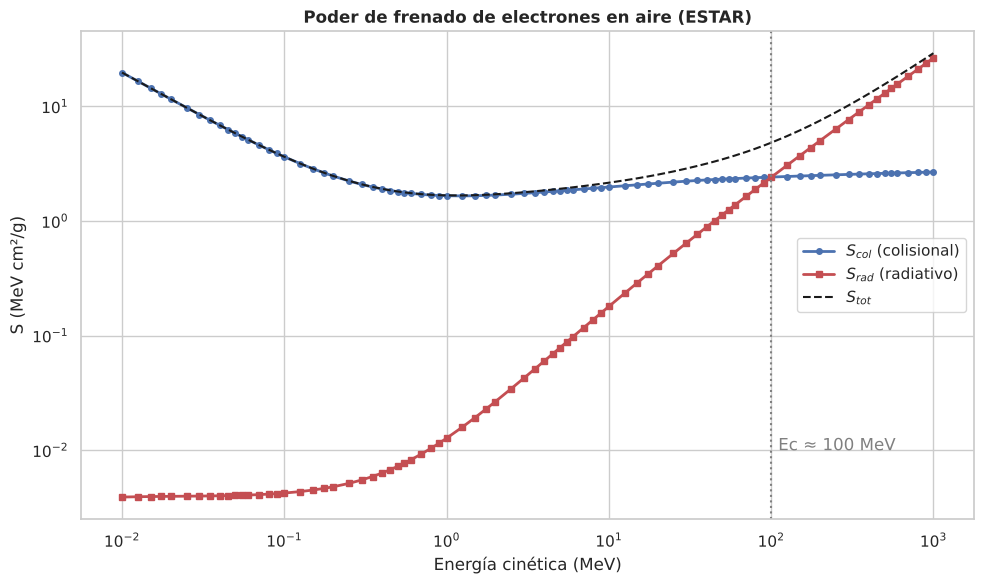

In [15]:
# =====================================================================
# 1. LECTURA DE DATOS
# =====================================================================
estar = pd.read_csv('data/datos_problema_2-9.csv', comment='#')
E_e = estar['E_MeV'].values
Scol_e = estar['S_col'].values
Srad_e = estar['S_rad'].values
Stot_e = Scol_e + Srad_e
rho_aire_p9 = 1.20e-3      # g/cm^3
E0_p9 = 700.0              # MeV
display(estar.head())

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
# Energía crítica: cruce de S_col y S_rad (interpolación en log)
dif = np.log(Scol_e / Srad_e)
i = np.where(np.diff(np.sign(dif)))[0][0]
Ec_p9 = np.exp(np.interp(0, [dif[i+1], dif[i]], [np.log(E_e[i+1]), np.log(E_e[i])]))

def yield_bremsstrahlung(E0, n=6000):
    E = np.logspace(np.log10(E_e[0]), np.log10(E0), n)
    y = interp_loglog(E, E_e, Srad_e) / (interp_loglog(E, E_e, Scol_e) + interp_loglog(E, E_e, Srad_e))
    return trapezoid(y, E) / E0

R_p9 = alcance_csda(E_e, Stot_e, E_e[0], E0_p9)
B_p9 = yield_bremsstrahlung(E0_p9)
ED_p9 = (1.0 - B_p9) * E0_p9

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 9)                    ")
print("=====================================================================")
i_min = np.argmin(Scol_e)
print(f"Mínimo de S_col: {Scol_e[i_min]:.3f} MeV cm²/g a E = {E_e[i_min]:.2f} MeV")
print(f"Energía crítica (S_col = S_rad): Ec ≈ {Ec_p9:.1f} MeV")
print("-" * 69)
print(f"Recorrido CSDA de un e- de {E0_p9:.0f} MeV: R = {R_p9:.2f} g/cm²  ->  {R_p9/rho_aire_p9/100:.0f} m de aire")
print(f"Bremsstrahlung yield B({E0_p9:.0f} MeV) = {B_p9:.3f}")
print(f"Energía radiada:    {B_p9*E0_p9:.1f} MeV")
print(f"Energía depositada: {ED_p9:.1f} MeV")
print("=====================================================================")

# =====================================================================
# 4. GRÁFICA
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 6))
ax.loglog(E_e, Scol_e, 'o-', color='#4c72b0', ms=4, lw=2, label=r'$S_{col}$ (colisional)')
ax.loglog(E_e, Srad_e, 's-', color='#c44e52', ms=4, lw=2, label=r'$S_{rad}$ (radiativo)')
ax.loglog(E_e, Stot_e, color='k', lw=1.5, ls='--', label=r'$S_{tot}$')
ax.axvline(Ec_p9, color='gray', ls=':')
ax.text(Ec_p9 * 1.1, 0.01, f'Ec ≈ {Ec_p9:.0f} MeV', color='gray')
ax.set_xlabel('Energía cinética (MeV)'); ax.set_ylabel('S (MeV cm²/g)')
ax.set_title('Poder de frenado de electrones en aire (ESTAR)', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

#### **Bonus: Recorrido y *bremsstrahlung yield* en función de la energía**

El *bremsstrahlung yield* tiene una interpretación geométrica sencilla: si representamos la fracción radiativa $y(E) = S_{rad}/S_{tot}$ en escala **lineal** de energía, $B(E_0)\,E_0$ es el **área bajo la curva** entre 0 y $E_0$, es decir, la energía radiada. El área complementaria (hasta $y = 1$) es la energía depositada.

**Cuestiones:**
1. ¿Para qué energía se radia la mitad de la energía inicial ($B = 0.5$)? ¿Coincide con la energía crítica? ¿Por qué no?
2. ¿Cómo crece el recorrido $R$ con $E_0$ a baja energía (< 1 MeV) y a alta energía (> 100 MeV)?
3. Busca la energía a partir de la cual un electrón deposita menos del 50 % de su energía en el aire.

In [16]:
def explorador_electrones_aire(E0_w):
    E = np.logspace(np.log10(E_e[0]), np.log10(E0_w), 3000)
    y = interp_loglog(E, E_e, Srad_e) / (interp_loglog(E, E_e, Srad_e) + interp_loglog(E, E_e, Scol_e))
    B = trapezoid(y, E) / E0_w
    R = alcance_csda(E_e, Stot_e, E_e[0], E0_w)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    ax = axes[0]
    ax.fill_between(E, 0, y, color='#c44e52', alpha=0.6, label=f'Radiada: {B*E0_w:.3g} MeV')
    ax.fill_between(E, y, 1, color='#4c72b0', alpha=0.6, label=f'Depositada: {(1-B)*E0_w:.3g} MeV')
    ax.set_xlim(0, E0_w); ax.set_ylim(0, 1)
    ax.set_xlabel('E (MeV) — escala lineal'); ax.set_ylabel(r'$S_{rad}/S_{tot}$')
    ax.set_title(f'B({E0_w:.3g} MeV) = {B:.3f}', fontweight='bold')
    ax.legend(loc='upper left')

    ax = axes[1]
    E_g = np.logspace(np.log10(0.02), 3, 120)
    R_g = np.array([alcance_csda(E_e, Stot_e, E_e[0], e, n=800) for e in E_g])
    ax.loglog(E_g, R_g, color='k', lw=2)
    ax.plot(E0_w, R, 'o', color='gold', mec='k', ms=11)
    ax.set_xlabel('E₀ (MeV)'); ax.set_ylabel('R (g/cm²)')
    ax.set_title(f'Recorrido CSDA: R = {R:.3g} g/cm² = {R/rho_aire_p9/100:.3g} m de aire', fontweight='bold')
    plt.tight_layout(); plt.show()

interact(explorador_electrones_aire,
         E0_w=widgets.FloatLogSlider(value=700, base=10, min=-1.5, max=3, step=0.02,
                                     description='E₀ (MeV)', continuous_update=False));

### **Problema 10**
Empleando los datos de poder de frenado colisional $S_{col}$ de rayos $\alpha$ en cierto medio (ver datos en el CV), resolver las siguientes cuestiones:

* Representar gráficamente $S_{col}$ frente a la energía $E$.
* Calcular el alcance $R$ de una partícula $\alpha$ de 5 MeV en ese medio y representar la correspondiente curva de Bragg.
* Hallar la distancia a la cual la partícula $\alpha$ ha depositado el 50 % de su energía.

*(Datos en `data/datos_problema_2-10.csv`: energía cinética entre 1 keV y 10 MeV.)*

---

#### **1. Poder de frenado**
La curva $S_{col}(E)$ muestra la forma típica de un ion pesado: a alta energía decrece como $\sim 1/\beta^2 \propto 1/E$ (régimen de Bethe-Bloch), alcanza un **máximo** de $\approx 2020$ MeV cm²/g en torno a $E \approx 0.7$ MeV, y por debajo disminuye porque la partícula $\alpha$ empieza a **capturar electrones** (su carga efectiva disminuye) y porque su velocidad se hace comparable a la de los electrones del medio.

#### **2. Alcance de una partícula $\alpha$ de 5 MeV**
$$ R(5\text{ MeV}) = \int_{0}^{5} \frac{dE}{S_{col}(E)} \approx \int_{0.001}^{5} \frac{dE}{S_{col}(E)} \approx \mathbf{4.36\times10^{-3}\text{ g cm}^{-2}} $$
(el tramo por debajo de 1 keV es despreciable).

#### **3. Curva de Bragg**
Para cada energía $E$ de la trayectoria, la profundidad alcanzada es $x(E) = R(E_0) - R(E)$, y la energía depositada por unidad de espesor es $S(E)$. Representando $S(E(x))$ frente a $x$ obtenemos la curva de Bragg, con su máximo muy cerca del final del recorrido.

#### **4. Distancia a la que se ha depositado el 50 % de la energía**
Se habrá depositado la mitad de la energía cuando $E = E_0/2 = 2.5$ MeV:
$$ x_{50\%} = R(5) - R(2.5) = \int_{2.5}^{5}\frac{dE}{S(E)} \approx \mathbf{2.69\times10^{-3}\text{ g cm}^{-2}} $$
Esto supone el **62 % del alcance**: la segunda mitad de la energía se deposita en sólo el 38 % final del recorrido, reflejo del aumento de $S$ al frenarse la partícula.

> **¿Qué medio es?** Compara los datos con la gráfica del Problema 1: ¡coinciden exactamente con la curva del **aire**! Con $\rho = 1.2\times10^{-3}$ g/cm³ el alcance es $R \approx 3.64$ cm (compatible con la estimación de 3.6 cm del Problema 1) y el 50 % de la energía se deposita en los primeros 2.24 cm. Para aire en condiciones NTP (1 atm, 20 °C, $\rho = 1.205\times10^{-3}$ g/cm³) se obtiene $R = 3.62$ cm y $x_{50} = 2.23$ cm; para aire ISA (15 °C, $\rho = 1.230\times10^{-3}$ g/cm³), $R = 3.54$ cm y $x_{50} = 2.19$ cm.

                RESULTADOS NUMÉRICOS (PROBLEMA 10)                   
Máximo de S: 2021 MeV cm²/g a E = 0.70 MeV
Alcance de α de 5.0 MeV:            R = 4.364e-03 g/cm²
Profundidad con 50% de energía depositada: x = 2.694e-03 g/cm²  (61.7% de R)
Posición del pico de Bragg:               x = 3.851e-03 g/cm²  (88.2% de R)
---------------------------------------------------------------------
Si el medio es aire (ρ = 0.0012 g/cm³):
   R = 3.64 cm,   x(50%) = 2.24 cm
   R(0.5 MeV) = 0.34 cm (dato del Problema 1: 0.3 cm)


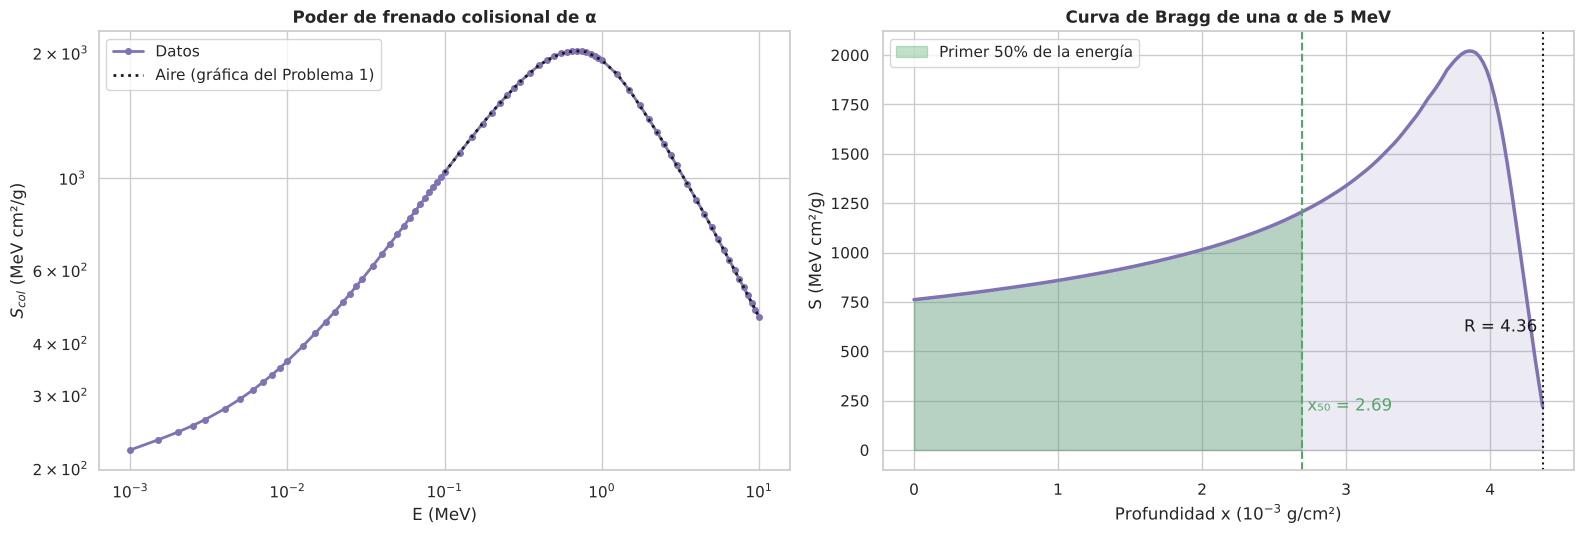

In [17]:
# =====================================================================
# 1. LECTURA DE DATOS
# =====================================================================
astar = pd.read_csv('data/datos_problema_2-10.csv', comment='#')
E_a, S_a = astar['E_MeV'].values, astar['S_col'].values
E0_p10 = 5.0
rho_hipotesis = 1.2e-3     # g/cm^3 (si el medio es aire)

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
R_p10 = alcance_csda(E_a, S_a, E_a[0], E0_p10)
R_mitad = alcance_csda(E_a, S_a, E_a[0], E0_p10 / 2)
x_50 = R_p10 - R_mitad
x_bragg, E_bragg, S_bragg = curva_bragg(E_a, S_a, E0_p10, E_a[0])
i_pico = np.argmax(S_bragg)

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 10)                   ")
print("=====================================================================")
print(f"Máximo de S: {S_a.max():.0f} MeV cm²/g a E = {E_a[np.argmax(S_a)]:.2f} MeV")
print(f"Alcance de α de {E0_p10} MeV:            R = {R_p10:.3e} g/cm²")
print(f"Profundidad con 50% de energía depositada: x = {x_50:.3e} g/cm²  ({100*x_50/R_p10:.1f}% de R)")
print(f"Posición del pico de Bragg:               x = {x_bragg[i_pico]:.3e} g/cm²  ({100*x_bragg[i_pico]/R_p10:.1f}% de R)")
print("-" * 69)
print(f"Si el medio es aire (ρ = {rho_hipotesis} g/cm³):")
print(f"   R = {R_p10/rho_hipotesis:.2f} cm,   x(50%) = {x_50/rho_hipotesis:.2f} cm")
print(f"   R(0.5 MeV) = {alcance_csda(E_a, S_a, E_a[0], 0.5)/rho_hipotesis:.2f} cm (dato del Problema 1: 0.3 cm)")
print("=====================================================================")

# =====================================================================
# 4. GRÁFICAS
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ax = axes[0]
ax.loglog(E_a, S_a, 'o-', color='#8172b3', ms=4, lw=2, label='Datos')
if 'E_graf' in globals():   # curva del aire digitalizada en el Problema 1
    ax.loglog(E_graf, S_aire_graf, 'k:', lw=2, label='Aire (gráfica del Problema 1)')
ax.set_xlabel('E (MeV)'); ax.set_ylabel(r'$S_{col}$ (MeV cm²/g)')
ax.set_title('Poder de frenado colisional de α', fontweight='bold')
ax.legend()

ax = axes[1]
ax.plot(x_bragg * 1e3, S_bragg, color='#8172b3', lw=2.5)
ax.fill_between(x_bragg * 1e3, S_bragg, color='#8172b3', alpha=0.15)
ax.fill_between(x_bragg * 1e3, S_bragg, where=x_bragg <= x_50, color='#55a868', alpha=0.35,
                label='Primer 50% de la energía')
ax.axvline(x_50 * 1e3, color='#55a868', ls='--')
ax.axvline(R_p10 * 1e3, color='k', ls=':')
ax.text(x_50 * 1e3, 200, f' x₅₀ = {x_50*1e3:.2f}', color='#55a868')
ax.text(R_p10 * 1e3, 600, f'R = {R_p10*1e3:.2f} ', color='k', ha='right')
ax.set_xlabel(r'Profundidad x ($10^{-3}$ g/cm²)'); ax.set_ylabel('S (MeV cm²/g)')
ax.set_title('Curva de Bragg de una α de 5 MeV', fontweight='bold')
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

#### **Bonus: Curva de Bragg interactiva**

Modifica la energía inicial de las partículas $\alpha$ y observa cómo cambian el alcance, la posición del pico de Bragg y el punto en el que se ha depositado el 50 % de la energía. El widget incluye una opción para **suavizar** la curva con el *straggling* en alcance (convolución con una gaussiana de anchura $\sigma_R \approx 1.2\%\,R$), que es lo que se mide realmente en un experimento con un haz de muchas partículas.

**Cuestiones:**
1. ¿Cómo escala el alcance con la energía inicial? Ajusta una ley $R \propto E_0^{\,n}$ con los valores obtenidos para 2, 4 y 8 MeV. ¿Recuperas la regla de Geiger ($n = 3/2$)?
2. ¿Por qué la altura del pico de Bragg (sin *straggling*) es la misma para cualquier $E_0$ mayor que 0.7 MeV?
3. ¿Qué le ocurre a la curva de Bragg cuando $E_0 < 0.7$ MeV?

In [18]:
def bragg_interactivo(E0_w, straggling):
    x, E, S = curva_bragg(E_a, S_a, E0_w, E_a[0], n=4000)
    R = x[-1]
    R_med = alcance_csda(E_a, S_a, E_a[0], E0_w / 2)
    x50 = R - R_med

    fig, ax = plt.subplots(figsize=(11, 5.5))
    ax.plot(x * 1e3, S, color='#8172b3', lw=2.5, label='CSDA (sin straggling)')
    if straggling:
        sigma = 0.012 * R
        xg = np.linspace(0, 1.15 * R, 1500)
        Sg = np.interp(xg, x, S, right=0.0)
        dxg = xg[1] - xg[0]
        nucleo = np.arange(-5 * sigma, 5 * sigma + dxg, dxg)
        g = np.exp(-0.5 * (nucleo / sigma)**2); g /= g.sum()
        npad = len(g) // 2   # relleno para evitar artefactos de borde en x = 0
        Sg_pad = np.concatenate([np.full(npad, Sg[0]), Sg, np.zeros(npad)])
        S_conv = np.convolve(Sg_pad, g, mode='same')[npad:npad + len(Sg)]
        ax.plot(xg * 1e3, S_conv, color='#dd8452', lw=2.5,
                label=f'Con straggling (σR = {sigma*1e3:.3f}·10⁻³ g/cm²)')
    ax.axvline(x50 * 1e3, color='#55a868', ls='--', label=f'50% de la energía: {x50*1e3:.3f}·10⁻³ g/cm²')
    ax.axvline(R * 1e3, color='k', ls=':', label=f'Alcance: {R*1e3:.3f}·10⁻³ g/cm² ({R/1.2e-3:.2f} cm de aire)')
    ax.set_xlim(0, 1.15 * R * 1e3); ax.set_ylim(0, 2300)
    ax.set_xlabel(r'Profundidad x ($10^{-3}$ g/cm²)'); ax.set_ylabel('S (MeV cm²/g)')
    ax.set_title(f'Curva de Bragg de partículas α de {E0_w:.2f} MeV', fontweight='bold')
    ax.legend(loc='upper left', fontsize=9)
    plt.tight_layout(); plt.show()
    print(f"E0 = {E0_w:.2f} MeV  ->  R = {R:.4e} g/cm²,  x(50%)/R = {x50/R:.3f}")

interact(bragg_interactivo,
         E0_w=widgets.FloatSlider(value=5.0, min=0.3, max=10.0, step=0.1, description='E₀ (MeV)',
                                  continuous_update=False),
         straggling=widgets.Checkbox(value=False, description='Incluir straggling'));

### **Problema 11**
El poder de frenado de protones en un medio material puede ser descrito de manera aproximada por la siguiente expresión:
$$ -\frac{dE}{dx} = a\times E^{-b} \quad \text{para } E < E_t; \qquad -\frac{dE}{dx} = \alpha \quad \text{para } E > E_t $$
en donde $a$, $b$ y $\alpha$ son parámetros positivos.

**a)** Obtener una expresión analítica $E(x)$ que permita calcular la energía de un protón después de haber recorrido una distancia $x$ suponiendo que inicia su recorrido ($x = 0$) con $E = E_0 > E_t$. Obtener una expresión para el alcance, $R(E_0)$.

**b)** Obtener una expresión analítica que permita calcular la energía depositada por el protón en el medio por unidad de longitud ($dE/dx$), en función de la distancia $x$ y suponiendo de nuevo que inicia su recorrido con $E = E_0 > E_t$.

**c)** Hallar la energía depositada por unidad de longitud (MeV/cm) para protones de 2.0 GeV después de haber recorrido en agua una longitud $x = 500$ cm. Repetir el cálculo para $x = 800$ cm. Hallar el alcance del protón. Expresando la energía en MeV y la longitud en cm, los parámetros para el agua valen: $a = 264$, $b = 0.77$, $\alpha = 2.20$ y $E_t = 500$.

**d)** Empleando los datos numéricos del poder de frenado de protones en agua (ver tabla en el CV), obtener numéricamente las funciones $E(x)$ y $(dE/dx)$ para protones de 2.0 GeV y compararlas con las predicciones de las expresiones analíticas usando los parámetros del apartado c). Comparar el alcance obtenido con el método analítico y el de los datos.

---

#### **a) Energía $E(x)$ y alcance $R(E_0)$**

**Tramo 1 ($E > E_t$):** pérdida constante, $dE/dx = -\alpha$:
$$ E(x) = E_0 - \alpha x, \qquad 0 \le x \le x_t \equiv \frac{E_0 - E_t}{\alpha} $$
donde $x_t$ es la distancia a la que el protón alcanza la energía $E_t$.

**Tramo 2 ($E < E_t$):** $dE/dx = -aE^{-b}$. Separando variables desde $(x_t, E_t)$:
$$ E^{b}\,dE = -a\,dx \;\Longrightarrow\; \frac{E^{b+1} - E_t^{b+1}}{b+1} = -a\,(x - x_t) $$
$$ E(x) = \Big[E_t^{\,b+1} - a(b+1)(x - x_t)\Big]^{\frac{1}{b+1}}, \qquad x_t \le x \le R $$

**Alcance:** se alcanza cuando $E = 0$:
$$ \boxed{R(E_0) = \frac{E_0 - E_t}{\alpha} + \frac{E_t^{\,b+1}}{a(b+1)}} $$

#### **b) Energía depositada por unidad de longitud $dE/dx(x)$**
$$ -\frac{dE}{dx}(x) = \begin{cases} \alpha & 0 \le x \le x_t \\[2mm] a\,E(x)^{-b} = a\Big[E_t^{\,b+1} - a(b+1)(x - x_t)\Big]^{-\frac{b}{b+1}} & x_t < x < R \end{cases} $$
La segunda expresión **diverge** cuando $x \to R$: es el **pico de Bragg** (en la realidad $S$ alcanza un máximo finito a muy baja energía, que esta ley de potencias no reproduce).

#### **c) Protones de 2.0 GeV en agua** ($a = 264$, $b = 0.77$, $\alpha = 2.20$, $E_t = 500$)
* Distancia de transición: $x_t = (2000 - 500)/2.20 = 681.8$ cm.
* **$x = 500$ cm** $< x_t$ (tramo de pérdida constante):
$$ E = 2000 - 2.20 \times 500 = 900\text{ MeV}, \qquad -\frac{dE}{dx} = \mathbf{2.20\text{ MeV/cm}} $$
* **$x = 800$ cm** $> x_t$: con $E_t^{1.77} = 500^{1.77} = 5.987\times10^4$ y $a(b+1) = 467.3$:
$$ E^{1.77} = 5.987\times10^4 - 467.3 \times (800 - 681.8) = 4.65\times10^3 \;\Rightarrow\; E \approx 118\text{ MeV} $$
$$ -\frac{dE}{dx} = 264 \times 118^{-0.77} \approx \mathbf{6.7\text{ MeV/cm}} $$
* **Alcance:**
$$ R = 681.8 + \frac{5.987\times10^4}{467.3} = 681.8 + 128.1 \approx \mathbf{810\text{ cm}} $$

#### **d) Comparación con los datos tabulados (PSTAR)**
Integramos numéricamente $dx = dE/S(E)$ con los datos de la tabla. Construimos el alcance residual $R(E)$ y lo invertimos: $E(x)$ es la energía cuyo alcance residual vale $R(E_0) - x$. Los resultados (celda siguiente) muestran un acuerdo excelente en el **alcance**: $\approx 804$ cm (numérico) frente a 810 cm (analítico), una diferencia $< 1\%$.

| $x$ (cm) | $E$ analítica | $E$ numérica | $-dE/dx$ analítico | $-dE/dx$ numérico |
| :---: | :---: | :---: | :---: | :---: |
| 500 | 900 MeV | 953 MeV | 2.20 MeV/cm | 2.23 MeV/cm |
| 800 | 118 MeV | 72 MeV | 6.7 MeV/cm | 9.3 MeV/cm |

A 500 cm el acuerdo es muy bueno. A 800 cm las diferencias son mayores, pero no porque el modelo sea malo: cerca del final del recorrido $E(x)$ cae muy deprisa, y una diferencia de sólo $\sim 6$ cm en el alcance se traduce en una diferencia grande en la energía y en $dE/dx$ a una profundidad fija. Las mayores discrepancias aparecen en el pico de Bragg, donde la expresión analítica diverge.

                RESULTADOS NUMÉRICOS (PROBLEMA 11)                   
Distancia de transición x_t = 681.8 cm
---------------------------------------------------------------------
 x (cm) | E anal. (MeV) |  dE/dx anal. | E num. (MeV) |  dE/dx num.
---------------------------------------------------------------------
    500 |         900.0 |     2.20 MeV/cm |        953.1 |    2.23 MeV/cm
    800 |         117.9 |     6.71 MeV/cm |         72.2 |    9.33 MeV/cm
---------------------------------------------------------------------
Alcance analítico:  R = 809.9 cm
Alcance numérico:   R = 804.3 cm   (diferencia +0.70%)
  (el alcance por debajo de 1 MeV, límite inferior de la tabla, es ~0.002 cm: despreciable)


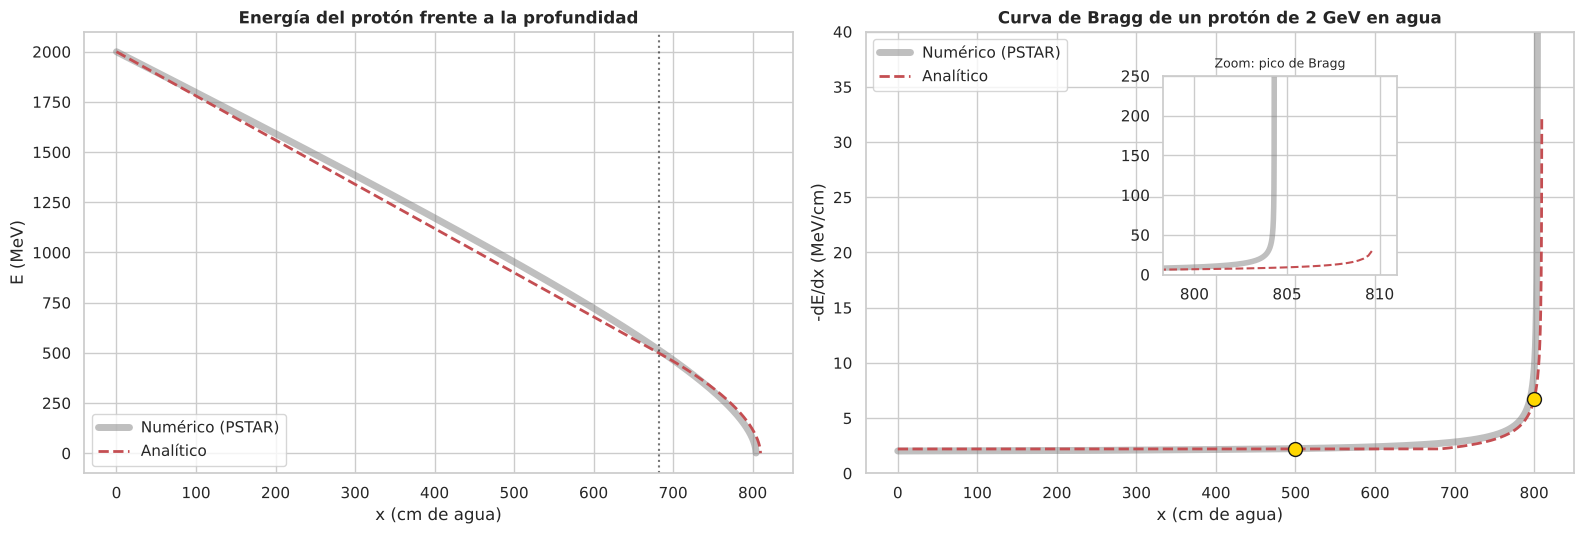

In [19]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
a11, b11, alpha11, Et11 = 264.0, 0.77, 2.20, 500.0   # MeV, cm (agua)

# Datos PSTAR (NIST) de poder de frenado de protones en agua
pstar = pd.read_csv('data/datos_problema_2-11.csv', comment='#')
E_pstar, S_pstar = pstar['E_MeV'].values, pstar['S'].values
E0_p11 = 2000.0                                     # MeV
rho_agua = 1.0

# =====================================================================
# 2. SOLUCIÓN ANALÍTICA
# =====================================================================
def x_transicion(E0):
    return max(E0 - Et11, 0.0) / alpha11

def R_analitico(E0):
    Ei = min(E0, Et11)
    return x_transicion(E0) + Ei**(b11 + 1) / (a11 * (b11 + 1))

def E_analitica(x, E0):
    x = np.asarray(x, dtype=float)
    xt = x_transicion(E0)
    Ei = min(E0, Et11)
    base = Ei**(b11 + 1) - a11 * (b11 + 1) * (x - xt)
    E_baja = np.where(base > 0, np.abs(base)**(1 / (b11 + 1)), 0.0)
    return np.where(x <= xt, E0 - alpha11 * x, E_baja)

def dEdx_analitica(x, E0):
    E = E_analitica(x, E0)
    with np.errstate(divide='ignore'):
        return np.where(E > Et11, alpha11, np.where(E > 0, a11 * E**(-b11), np.nan))

# =====================================================================
# 3. SOLUCIÓN NUMÉRICA CON LOS DATOS PSTAR
# =====================================================================
def solucion_numerica(E0, n=6000):
    x, E, S = curva_bragg(E_pstar, S_pstar, E0, E_pstar[0], n=n)
    return x / rho_agua, E, S * rho_agua      # cm, MeV, MeV/cm

x_num, E_num, S_num = solucion_numerica(E0_p11)
R_num = x_num[-1]
E_num_at = lambda xx: np.interp(xx, x_num, E_num)
S_num_at = lambda xx: np.interp(xx, x_num, S_num)

# =====================================================================
# 4. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 11)                   ")
print("=====================================================================")
print(f"Distancia de transición x_t = {x_transicion(E0_p11):.1f} cm")
print("-" * 69)
print(f"{'x (cm)':>7} | {'E anal. (MeV)':>13} | {'dE/dx anal.':>12} | {'E num. (MeV)':>12} | {'dE/dx num.':>11}")
print("-" * 69)
for xx in [500.0, 800.0]:
    print(f"{xx:7.0f} | {float(E_analitica(xx, E0_p11)):13.1f} | {float(dEdx_analitica(xx, E0_p11)):8.2f} MeV/cm"
          f" | {E_num_at(xx):12.1f} | {S_num_at(xx):7.2f} MeV/cm")
print("-" * 69)
print(f"Alcance analítico:  R = {R_analitico(E0_p11):.1f} cm")
print(f"Alcance numérico:   R = {R_num:.1f} cm   (diferencia {100*(R_analitico(E0_p11)-R_num)/R_num:+.2f}%)")
print("  (el alcance por debajo de 1 MeV, límite inferior de la tabla, es ~0.002 cm: despreciable)")
print("=====================================================================")

# =====================================================================
# 5. GRÁFICAS: E(x) y dE/dx(x)
# =====================================================================
x_plot = np.linspace(0, R_analitico(E0_p11), 3000)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ax = axes[0]
ax.plot(x_num, E_num, color='gray', lw=5, alpha=0.5, label='Numérico (PSTAR)')
ax.plot(x_plot, E_analitica(x_plot, E0_p11), color='#c44e52', lw=2, ls='--', label='Analítico')
ax.axvline(x_transicion(E0_p11), color='k', ls=':', alpha=0.6)
ax.set_xlabel('x (cm de agua)'); ax.set_ylabel('E (MeV)')
ax.set_title('Energía del protón frente a la profundidad', fontweight='bold')
ax.legend()

ax = axes[1]
ax.plot(x_num, S_num, color='gray', lw=5, alpha=0.5, label='Numérico (PSTAR)')
ax.plot(x_plot, dEdx_analitica(x_plot, E0_p11), color='#c44e52', lw=2, ls='--', label='Analítico')
for xx in [500, 800]:
    ax.plot(xx, dEdx_analitica(xx, E0_p11), 'o', color='gold', mec='k', ms=10)
ax.set_ylim(0, 40)
ax.set_xlabel('x (cm de agua)'); ax.set_ylabel('-dE/dx (MeV/cm)')
ax.set_title('Curva de Bragg de un protón de 2 GeV en agua', fontweight='bold')
ax.legend(loc='upper left')
ax_in = ax.inset_axes([0.42, 0.45, 0.33, 0.45])
ax_in.plot(x_num, S_num, color='gray', lw=4, alpha=0.5)
ax_in.plot(x_plot, dEdx_analitica(x_plot, E0_p11), color='#c44e52', lw=1.5, ls='--')
ax_in.set_xlim(R_num - 6, R_analitico(E0_p11) + 1); ax_in.set_ylim(0, 250)
ax_in.set_title('Zoom: pico de Bragg', fontsize=9)
plt.tight_layout(); plt.show()

#### **Bonus: Protonterapia — ¿dónde se deposita la dosis?**

La curva de Bragg es la base de la **protonterapia**: ajustando la energía del haz se sitúa el pico de Bragg (máximo depósito de energía) justo en el tumor, minimizando la dosis en los tejidos sanos situados delante y, sobre todo, **detrás** del tumor (donde la dosis es prácticamente nula). Las energías clínicas típicas están entre 70 y 250 MeV.

El widget compara la curva de Bragg analítica (Problema 11) y la numérica (datos PSTAR) para la energía elegida.

**Cuestiones:**
1. ¿Qué energía debe tener el haz para que el pico de Bragg esté a 15 cm de profundidad en agua (tejido blando)?
2. Para energías clínicas ($E_0 < 500$ MeV) sólo actúa la ley de potencias. ¿Qué precisión tiene el alcance analítico en ese rango?
3. ¿Qué cociente hay entre la dosis en el pico y la dosis a la entrada? ¿Cómo cambia con $E_0$? (Ten en cuenta que en la realidad el *straggling* y las reacciones nucleares reducen notablemente este cociente.)

In [20]:
def protonterapia(E0_w):
    xn, En, Sn = solucion_numerica(E0_w, n=4000)
    Rn = xn[-1]
    Ra = R_analitico(E0_w)
    xa = np.linspace(0, Ra * 0.9995, 3000)

    fig, ax = plt.subplots(figsize=(11, 5.5))
    ax.plot(xn, Sn, color='gray', lw=5, alpha=0.5, label=f'Numérico (PSTAR): R = {Rn:.2f} cm')
    ax.plot(xa, dEdx_analitica(xa, E0_w), color='#c44e52', lw=2, ls='--',
            label=f'Analítico: R = {Ra:.2f} cm')
    ax.axvspan(Rn * 0.97, Rn * 1.005, color='gold', alpha=0.3, label='Región del pico de Bragg')
    ax.set_xlim(0, 1.1 * max(Ra, Rn))
    ax.set_ylim(0, 1.15 * Sn.max())
    ax.set_xlabel('Profundidad en agua (cm)'); ax.set_ylabel('-dE/dx (MeV/cm)')
    ax.set_title(f'Curva de Bragg de protones de {E0_w:.0f} MeV en agua', fontweight='bold')
    ax.legend(loc='upper left')
    plt.tight_layout(); plt.show()
    print(f"Alcance numérico {Rn:.2f} cm | analítico {Ra:.2f} cm | diferencia {100*(Ra-Rn)/Rn:+.2f}%")
    print(f"dE/dx a la entrada: {Sn[0]:.2f} MeV/cm  |  máximo (numérico): {Sn.max():.0f} MeV/cm")
    print("Nota: el máximo numérico está limitado por el extremo inferior de la tabla PSTAR (1 MeV);")
    print("      el verdadero máximo de S en agua (~800 MeV cm²/g) se alcanza en torno a 80 keV.")

interact(protonterapia,
         E0_w=widgets.FloatSlider(value=150, min=20, max=2000, step=5, description='E₀ (MeV)',
                                  continuous_update=False));

### **Problema 12**
Para electrones con energía superior a 100 MeV en aire ($\rho = 1.20\times10^{-3}\text{ g cm}^{-3}$), los poderes de frenado colisional y radiativo se pueden calcular con las siguientes expresiones:
$$ \left(\frac{dE}{dx}\right)_{col} = 2.42; \qquad \left(\frac{dE}{dx}\right)_{rad} = 2.72\cdot10^{-2}\times E $$
en donde la energía está expresada en MeV y el espesor en g cm⁻².

**a)** Hallar la longitud de radiación (m) de electrones en aire.

**b)** Hallar el camino recorrido (m) y la energía depositada (MeV) por un electrón de 10 GeV hasta que su energía se reduce a 1 GeV.

**c)** Sabiendo que para electrones de 1 GeV el *bremsstrahlung yield* es $B = 0.760$, hallar su valor para 10 GeV.

---

#### **a) Longitud de radiación**
Como $(dE/dx)_{rad} = E/X_0$:
$$ X_0 = \frac{1}{2.72\times10^{-2}} = 36.8\text{ g cm}^{-2} \quad\Rightarrow\quad X_0 = \frac{36.8}{1.20\times10^{-3}}\text{ cm} = 3.06\times10^{4}\text{ cm} \approx \mathbf{306\text{ m}} $$
(La energía crítica correspondiente es $E_c = a/b = 2.42/0.0272 = 89.0$ MeV.)

#### **b) Tramo 10 GeV → 1 GeV**
Integrando $dX = -dE/(a + bE)$ (como en los Problemas 6 y 8):
$$ \Delta X = X_0 \ln\frac{a + bE_0}{a + bE_1} = 36.76 \ln\frac{2.42 + 272}{2.42 + 27.2} = 36.76 \ln(9.265) = 81.8\text{ g cm}^{-2} $$
$$ \Delta x = \frac{81.8}{1.20\times10^{-3}}\text{ cm} \approx \mathbf{682\text{ m}} $$
La energía depositada (pérdidas colisionales, constantes) es:
$$ E_D = a\,\Delta X = 2.42 \times 81.85 \approx \mathbf{198\text{ MeV}} $$
De los 9000 MeV perdidos, sólo un 2.2 % se deposita en el aire; el resto se radia.

#### **c) *Bremsstrahlung yield* a 10 GeV**
La energía depositada por el electrón de 10 GeV hasta pararse es la depositada en el tramo 10 → 1 GeV más la que deposita un electrón de 1 GeV hasta pararse:
$$ E_D(10\text{ GeV}) = 198.1 + (1 - 0.760)\times1000 = 198.1 + 240 = 438.1\text{ MeV} $$
$$ B(10\text{ GeV}) = 1 - \frac{E_D}{E_0} = 1 - \frac{438.1}{10^4} \approx \mathbf{0.956} $$

In [21]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
rho_aire_p12 = 1.20e-3   # g/cm^3
a12 = 2.42               # MeV cm²/g
b12 = 2.72e-2            # cm²/g
E0_p12, E1_p12 = 1.0e4, 1.0e3   # MeV
B_1GeV = 0.760

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
X0_p12 = 1.0 / b12
Ec_p12 = a12 / b12
DX_p12 = X0_p12 * np.log((a12 + b12 * E0_p12) / (a12 + b12 * E1_p12))
ED_p12 = a12 * DX_p12
ED_10GeV = ED_p12 + (1 - B_1GeV) * E1_p12
B_10GeV = 1 - ED_10GeV / E0_p12

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 12)                   ")
print("=====================================================================")
print(f"a) X0 = {X0_p12:.2f} g/cm²  =  {X0_p12/rho_aire_p12/100:.0f} m de aire   (Ec = {Ec_p12:.1f} MeV)")
print("-" * 69)
print(f"b) Tramo 10 GeV -> 1 GeV: ΔX = {DX_p12:.2f} g/cm²  =  {DX_p12/rho_aire_p12/100:.0f} m de aire")
print(f"   Energía depositada: {ED_p12:.1f} MeV   ({100*ED_p12/(E0_p12-E1_p12):.2f}% de la energía perdida)")
print("-" * 69)
print(f"c) E_D(10 GeV) = {ED_10GeV:.1f} MeV   ->   B(10 GeV) = {B_10GeV:.4f}")
print("=====================================================================")

                RESULTADOS NUMÉRICOS (PROBLEMA 12)                   
a) X0 = 36.76 g/cm²  =  306 m de aire   (Ec = 89.0 MeV)
---------------------------------------------------------------------
b) Tramo 10 GeV -> 1 GeV: ΔX = 81.85 g/cm²  =  682 m de aire
   Energía depositada: 198.1 MeV   (2.20% de la energía perdida)
---------------------------------------------------------------------
c) E_D(10 GeV) = 438.1 MeV   ->   B(10 GeV) = 0.9562


### **Problema 13**
A partir de los datos que se dan más abajo sobre la interacción de electrones en cierto medio material, resolver las siguientes cuestiones:

**a)** Calcular la longitud de radiación y la energía crítica para electrones en ese medio.

**b)** Calcular la energía depositada en ese medio por un electrón de 500 MeV hasta que se frena completamente. Hallar el parámetro $B$ (*bremsstrahlung yield*) para esa energía.

**DATOS:** En ese material un electrón de 1.00 GeV atravesando un espesor de 0.1 g cm⁻² deposita (colisiones) 0.227 MeV y radia 2.51 MeV. Se puede suponer que para energías superiores a 5.0 MeV el poder de frenado colisional es constante y el radiativo es proporcional a la energía del electrón; para energías inferiores las pérdidas radiativas son despreciables.

---

#### **a) Longitud de radiación y energía crítica**
Como 0.1 g/cm² es un espesor muy pequeño frente a la escala en la que cambia la energía de un electrón de 1 GeV, los poderes de frenado son:
$$ S_{col} = a = \frac{0.227}{0.1} = 2.27\text{ MeV cm}^2/\text{g}, \qquad S_{rad}(1\text{ GeV}) = \frac{2.51}{0.1} = 25.1\text{ MeV cm}^2/\text{g} $$
Como $S_{rad} = E/X_0$:
$$ X_0 = \frac{1000}{25.1} \approx \mathbf{39.8\text{ g cm}^{-2}}, \qquad E_c = a\,X_0 = 2.27 \times 39.84 \approx \mathbf{90.4\text{ MeV}} $$

#### **b) Energía depositada por un electrón de 500 MeV**
Dividimos el frenado en dos regiones:

* **De 500 MeV a 5 MeV** (modelo $S = a + E/X_0$). Generalizando el resultado del Problema 8 hasta una energía final $E_f$ cualquiera:
$$ E_{D,1} = a\,\Delta X = a X_0 \ln\frac{a + E_0/X_0}{a + E_f/X_0} = E_c \ln\frac{E_c + E_0}{E_c + E_f} $$
$$ E_{D,1} = 90.44 \times \ln\frac{90.44 + 500}{90.44 + 5} = 90.44 \times \ln(6.187) = 90.44 \times 1.822 \approx 164.8\text{ MeV} $$
(lo que corresponde a un recorrido $\Delta X = 72.6$ g/cm²).

* **Por debajo de 5 MeV:** no hay pérdidas radiativas, así que los 5 MeV restantes se depositan íntegramente: $E_{D,2} = 5$ MeV.

$$ E_D(500\text{ MeV}) = 164.8 + 5 \approx \mathbf{169.8\text{ MeV}} $$
$$ B(500\text{ MeV}) = 1 - \frac{E_D}{E_0} = 1 - \frac{169.8}{500} \approx \mathbf{0.660} $$

> El medio tiene $X_0 \approx 40$ g/cm² y $E_c \approx 90$ MeV, valores muy parecidos a los del agua o el aire (medios de $Z$ bajo).

                RESULTADOS NUMÉRICOS (PROBLEMA 13)                   
S_col = 2.27 MeV cm²/g,   S_rad(1 GeV) = 25.1 MeV cm²/g
a) Longitud de radiación X0 = 39.84 g/cm²
   Energía crítica       Ec = 90.44 MeV
---------------------------------------------------------------------
b) Tramo 500 -> 5 MeV:  ΔX = 72.61 g/cm²,  E_D = 164.8 MeV
   Tramo 5 -> 0 MeV:    E_D = 5.0 MeV
   Energía depositada total: 169.8 MeV
   Bremsstrahlung yield B(500 MeV) = 0.660


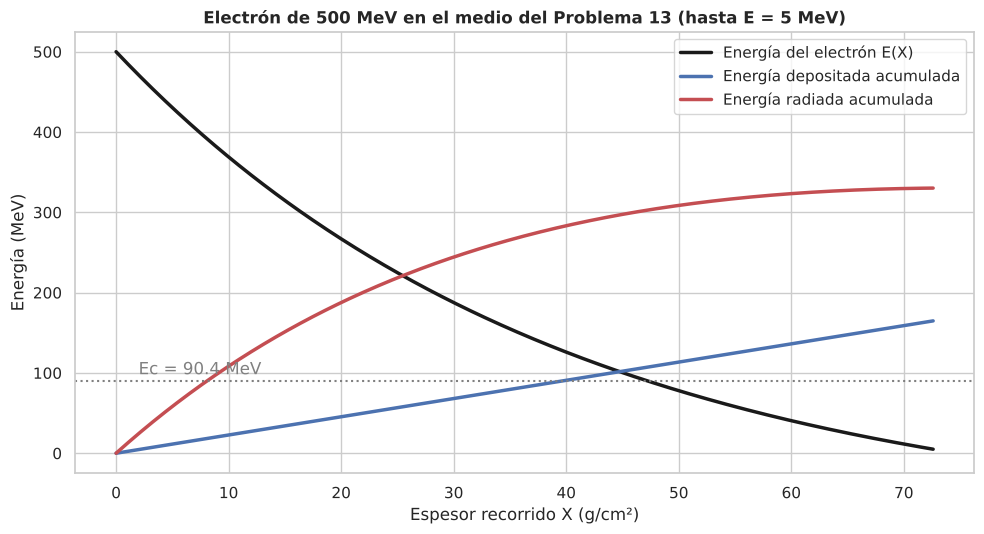

In [22]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
E_ref = 1000.0       # MeV
dX_ref = 0.1         # g/cm²
dE_col_ref = 0.227   # MeV
dE_rad_ref = 2.51    # MeV
E_lim = 5.0          # MeV (por debajo, sin pérdidas radiativas)
E0_p13 = 500.0       # MeV

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
a13 = dE_col_ref / dX_ref
S_rad_ref = dE_rad_ref / dX_ref
X0_p13 = E_ref / S_rad_ref
Ec_p13 = a13 * X0_p13

DX_p13 = X0_p13 * np.log((Ec_p13 + E0_p13) / (Ec_p13 + E_lim))
ED1_p13 = a13 * DX_p13
ED_p13 = ED1_p13 + E_lim
B_p13 = 1 - ED_p13 / E0_p13

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 13)                   ")
print("=====================================================================")
print(f"S_col = {a13:.2f} MeV cm²/g,   S_rad(1 GeV) = {S_rad_ref:.1f} MeV cm²/g")
print(f"a) Longitud de radiación X0 = {X0_p13:.2f} g/cm²")
print(f"   Energía crítica       Ec = {Ec_p13:.2f} MeV")
print("-" * 69)
print(f"b) Tramo 500 -> 5 MeV:  ΔX = {DX_p13:.2f} g/cm²,  E_D = {ED1_p13:.1f} MeV")
print(f"   Tramo 5 -> 0 MeV:    E_D = {E_lim:.1f} MeV")
print(f"   Energía depositada total: {ED_p13:.1f} MeV")
print(f"   Bremsstrahlung yield B(500 MeV) = {B_p13:.3f}")
print("=====================================================================")

# Gráfica: evolución de la energía y reparto de pérdidas a lo largo del recorrido
X_tr = np.linspace(0, DX_p13, 400)
E_tr = (Ec_p13 + E0_p13) * np.exp(-X_tr / X0_p13) - Ec_p13
ED_acum = a13 * X_tr
Erad_acum = (E0_p13 - E_tr) - ED_acum

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(X_tr, E_tr, color='k', lw=2.5, label='Energía del electrón E(X)')
ax.plot(X_tr, ED_acum, color='#4c72b0', lw=2.5, label='Energía depositada acumulada')
ax.plot(X_tr, Erad_acum, color='#c44e52', lw=2.5, label='Energía radiada acumulada')
ax.axhline(Ec_p13, color='gray', ls=':')
ax.text(2, Ec_p13 + 8, f'Ec = {Ec_p13:.1f} MeV', color='gray')
ax.set_xlabel('Espesor recorrido X (g/cm²)'); ax.set_ylabel('Energía (MeV)')
ax.set_title('Electrón de 500 MeV en el medio del Problema 13 (hasta E = 5 MeV)', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

---
### **Resumen de la Hoja 2**

| Concepto | Partículas cargadas pesadas ($p$, $\alpha$...) | Electrones |
| :--- | :--- | :--- |
| Mecanismo dominante | Colisiones (ionización/excitación) | Colisiones a baja energía; **radiación de frenado** por encima de $E_c$ |
| Poder de frenado | Bethe-Bloch: depende de $z^2$ y de $\beta$, no de la masa | $S_{col} \approx$ cte., $S_{rad} = E/X_0$ (alta energía) |
| Trayectoria | Casi rectilínea, **alcance bien definido** | Muy tortuosa a baja energía |
| Depósito de energía | **Curva de Bragg**: máximo al final del recorrido | Gran parte de la energía escapa como fotones ($B \to 1$ a alta energía) |
| Intensidad del haz | Constante hasta $x \approx R$ | — |
| Magnitudes clave | $R(E_0) = \int dE/S$ | $X_0$, $E_c$, $B(E_0)$, $\Delta x/X_0 = \ln\frac{E_c+E_0}{2E_c}$ |